#  

Each docked ensemble so far uses 5000 frames per ligand (5005 apo, 5000 holo, ~20,000 for
ligands 47 / 41 / 23). Here every completed ensemble is re-evaluated on **1000 evenly spaced
frames** and compared against the full ensemble for

1. the mean best-of-20 docking score per ligand,
2. the correlation of that score with the MD bound fraction,
3. per-residue interaction propensities (hydrophobic, aromatic, H-bond, charge).

If the 1000-frame results reproduce the full ones within their error bars, the remaining
ligands can be docked on 1000 frames, about a fifth of the cost.

**Error bars.** Frames are correlated, so sd/sqrt(N) understates the error. Every standard
error here is sd * sqrt(g / N), with g = 1 + 2 tau_int from the autocorrelation function and
Sokal's automatic window, as in `error_analysis.py`. Bars in the figures are 2 SE.

**Criterion.** A 1000-frame estimate agrees when the full-ensemble value lies within 2 SE of
it: would the error bar reported from 1000 frames have covered the 5000-frame answer? About
95% agreement is what sampling noise alone produces.

Per-frame contacts are computed with `docking_tools` exactly as in the per-job notebooks and
cached under `stride_test/cache/`, so re-running this notebook is fast.

In [1]:
import os, sys
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

sys.path.insert(0, os.path.abspath(os.path.join(os.getcwd(), "..", "workstation")))
import stride_test as st

In [2]:
N_FRAMES = 1000          # frames per ligand in the subset
JOBS = ['apo_pilot10', 'holo_pilot10', 'apo_remaining37', 'trio_apo']
BF_CSV = None            # MD bound fractions: CSV with ligand, bf[, bf_se] columns.
                         # None = look under hpc_results/error_analysis/

st.N_SUB = N_FRAMES
jobs = [j for j in JOBS if os.path.isdir(os.path.join(st.TRAJ, j))]
print("jobs:", jobs)

jobs: ['apo_pilot10', 'holo_pilot10', 'apo_remaining37', 'trio_apo']


## Run the test

In [3]:
srows, prows, profs = st.run(jobs, outdir=st.OUT)

=== apo_pilot10: 10 ligands
  lig3   score -5.477+/-0.071 vs -5.488+/-0.079 ok | propensities within 2SE: 99%


  lig5   score -4.579+/-0.088 vs -4.582+/-0.078 ok | propensities within 2SE: 96%


  lig9   score -5.302+/-0.104 vs -5.297+/-0.093 ok | propensities within 2SE: 99%


  lig17  score -5.148+/-0.105 vs -5.154+/-0.094 ok | propensities within 2SE: 92%


  lig24  score -5.056+/-0.093 vs -5.062+/-0.082 ok | propensities within 2SE: 99%


...

  lig56  score -5.166+/-0.109 vs -5.164+/-0.099 ok | propensities within 2SE: 100%


=== trio_apo: 3 ligands


  lig23  score -4.933+/-0.070 vs -4.909+/-0.061 ok | propensities within 2SE: 97%


  lig41  score -4.942+/-0.064 vs -4.957+/-0.063 ok | propensities within 2SE: 96%


  lig47  score -5.295+/-0.102 vs -5.290+/-0.100 ok | propensities within 2SE: 97%


## 1. Docking score: full ensemble vs 1000 frames

Each point is one ligand: mean best-of-20 score from the full ensemble (x) against the
1000-frame subset (y), with 1 SE bars. Blue = agrees within 2 SE, red = does not.

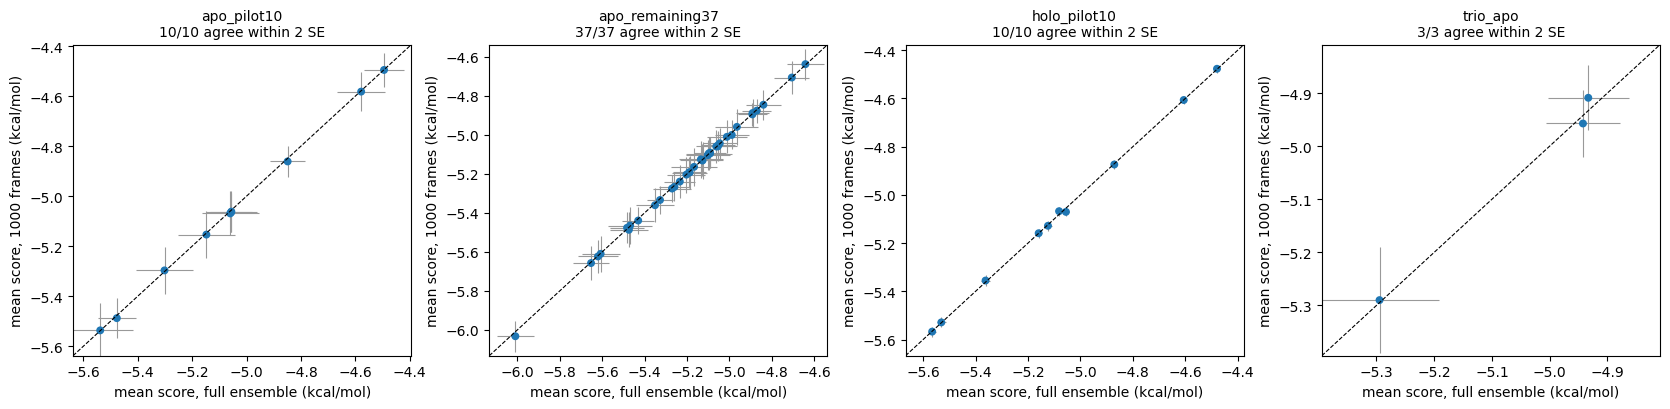

In [4]:
fig = st.plot_scores(srows)
plt.show()

## 2. MD bound fraction vs docking score

Mean docking score against the MD bound fraction, from the full ensemble (filled) and from
1000 frames (open). `r` is the Pearson correlation; `partial r` controls for ligand
heavy-atom count, since both quantities scale with molecular size.

MD bound fractions: 50 ligands from /home/zhihanz/data/VinaGPU/hpc_results/error_analysis/md_bound_fraction_all.csv (columns ligand, bf, bf_se)


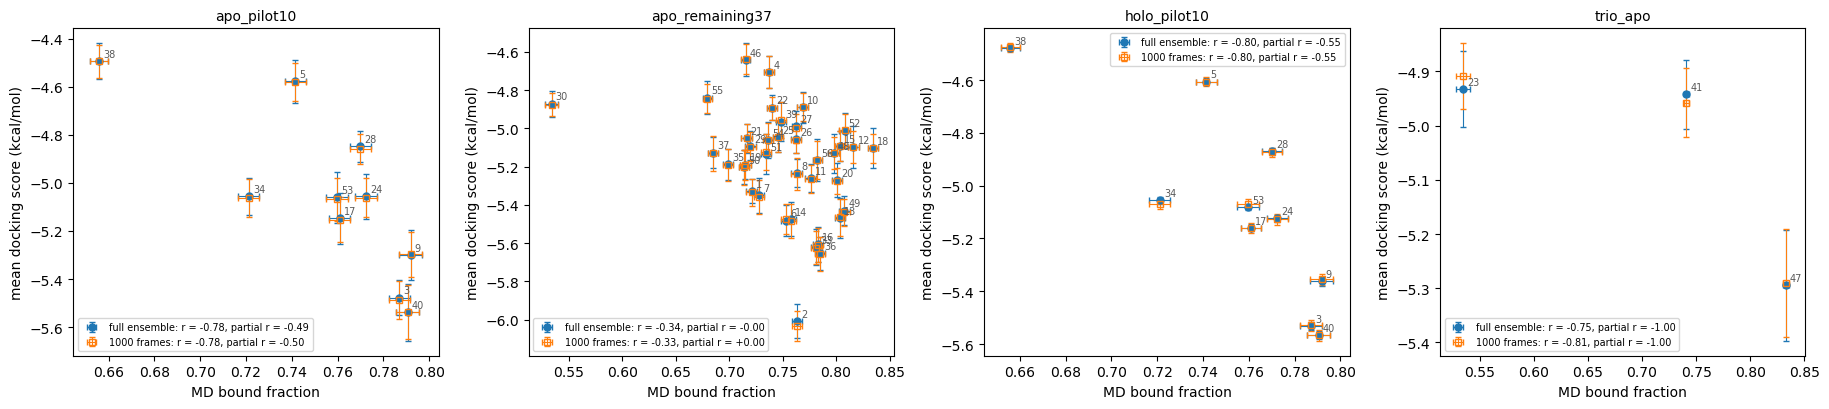

apo_pilot10      full         n=10  r=-0.775  partial r=-0.490
apo_pilot10      1000 frames  n=10  r=-0.777  partial r=-0.497
apo_remaining37  full         n=37  r=-0.338  partial r=-0.005
apo_remaining37  1000 frames  n=37  r=-0.333  partial r=+0.004
holo_pilot10     full         n=10  r=-0.802  partial r=-0.549
holo_pilot10     1000 frames  n=10  r=-0.799  partial r=-0.547
trio_apo         full         n=3   r=-0.752  partial r=-1.000
trio_apo         1000 frames  n=3   r=-0.811  partial r=-1.000


In [5]:
bf = st.load_bf(BF_CSV)
if bf:
    fig, summary = st.plot_md_vs_score(srows, bf)
    if fig is not None:
        plt.show()
        for s in summary:
            print(f"{s['job']:16s} {('full' if s['sample'] == 'full' else str(N_FRAMES) + ' frames'):12s} "
                  f"n={s['n']:<3d} r={s['r']:+.3f}  partial r={s['partial_r']:+.3f}")
    else:
        print("fewer than 3 ligands with MD bound fractions in any job")
else:
    print("No MD bound fractions found. Set BF_CSV to a CSV with ligand and bf columns.")

## 3. Interaction propensities with error bars

Per-residue propensity of each interaction type, full ensemble (grey) and 1000 frames
(blue), with 2 SE bars. One row per ligand.

### apo_pilot10

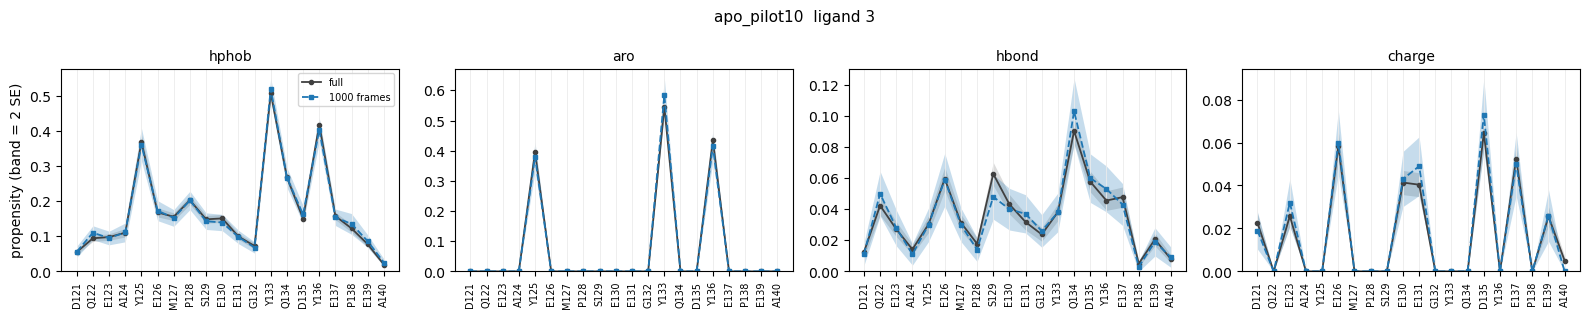

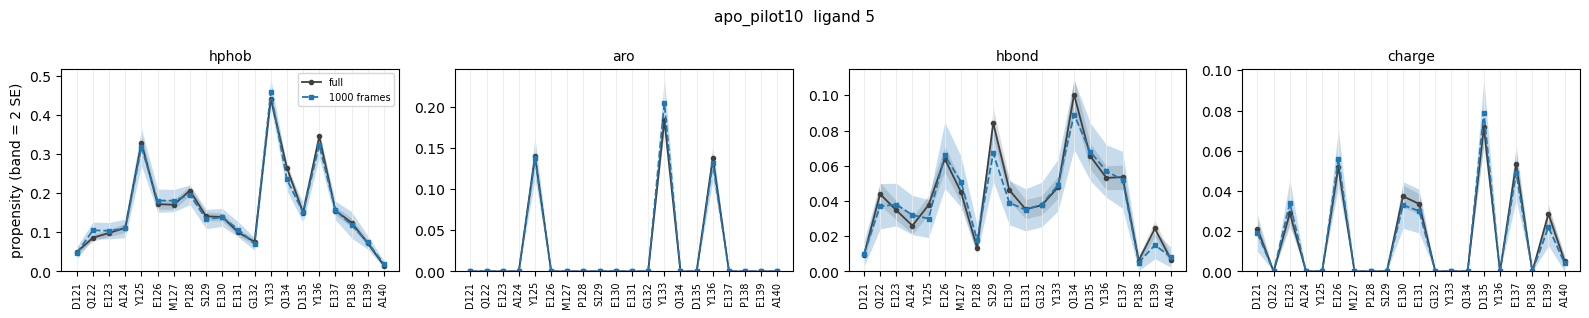

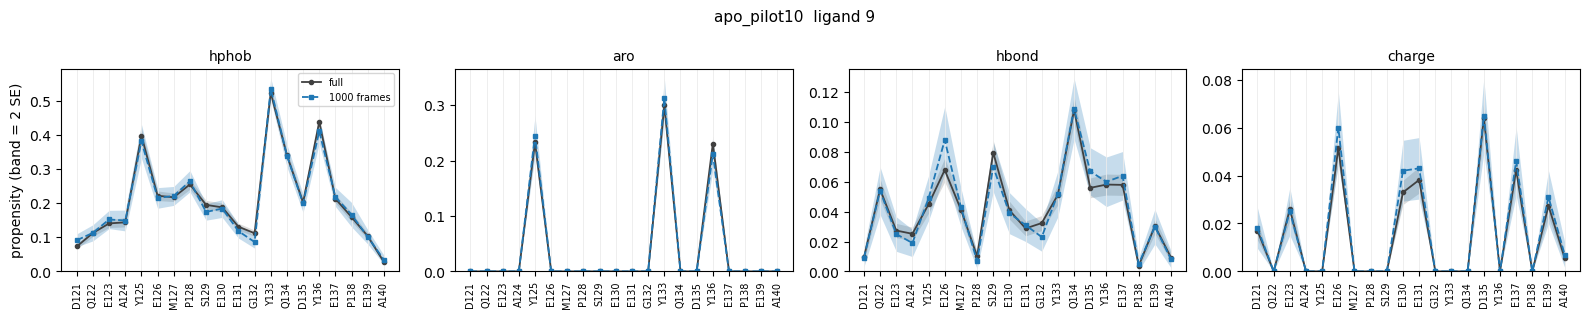

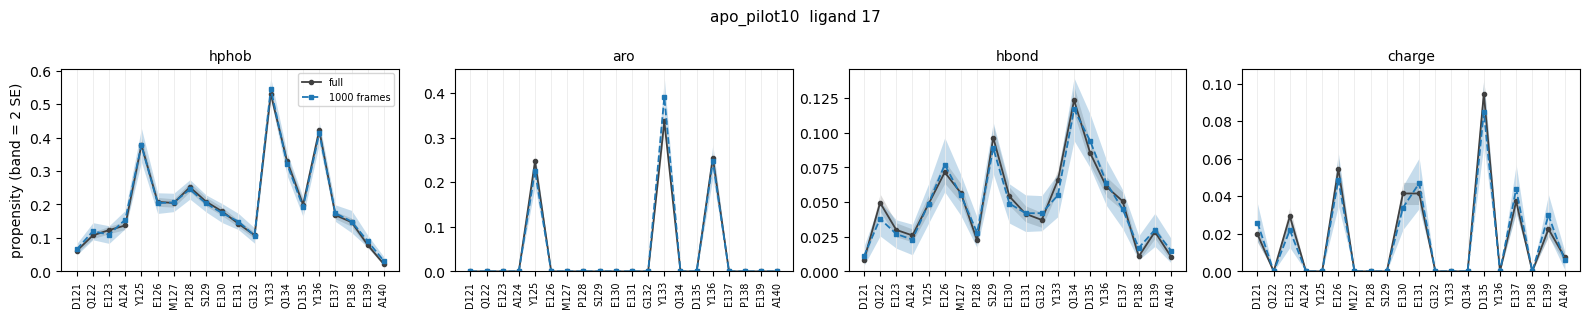

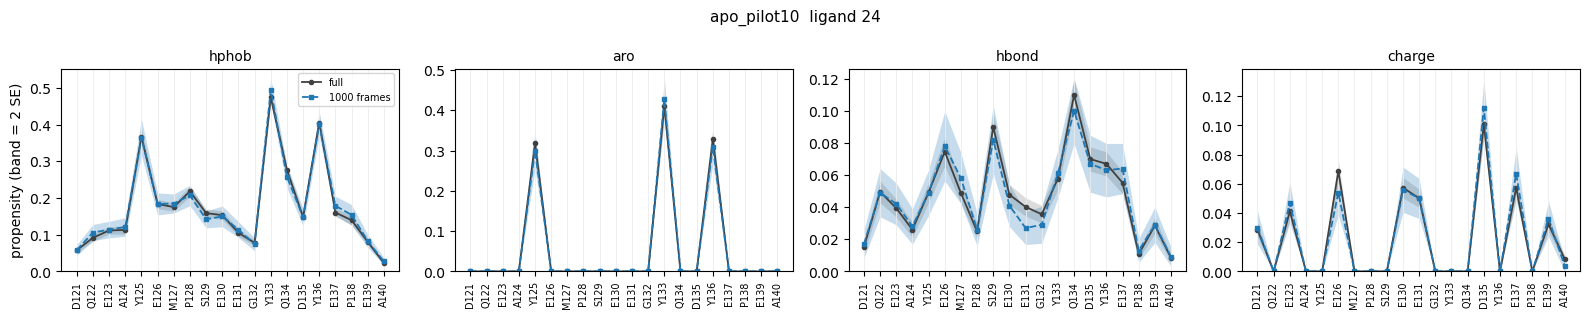

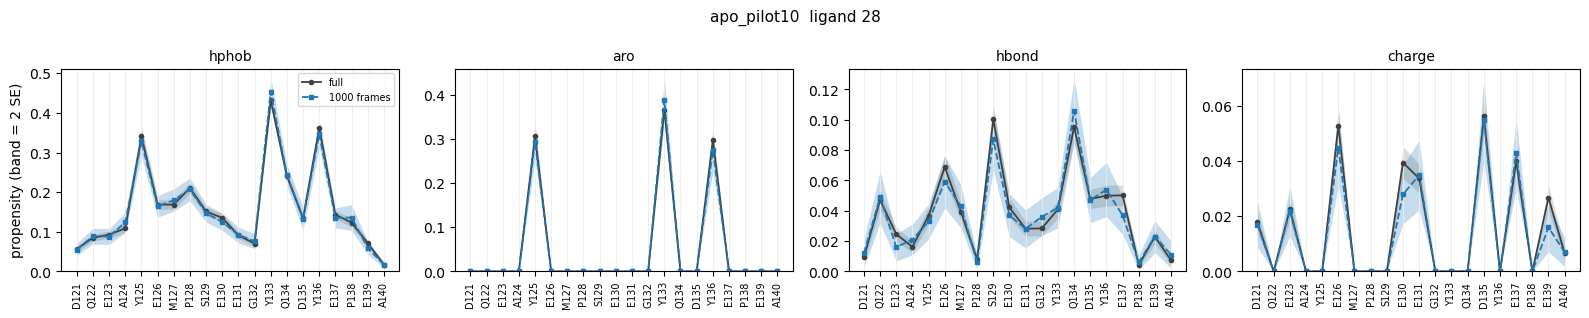

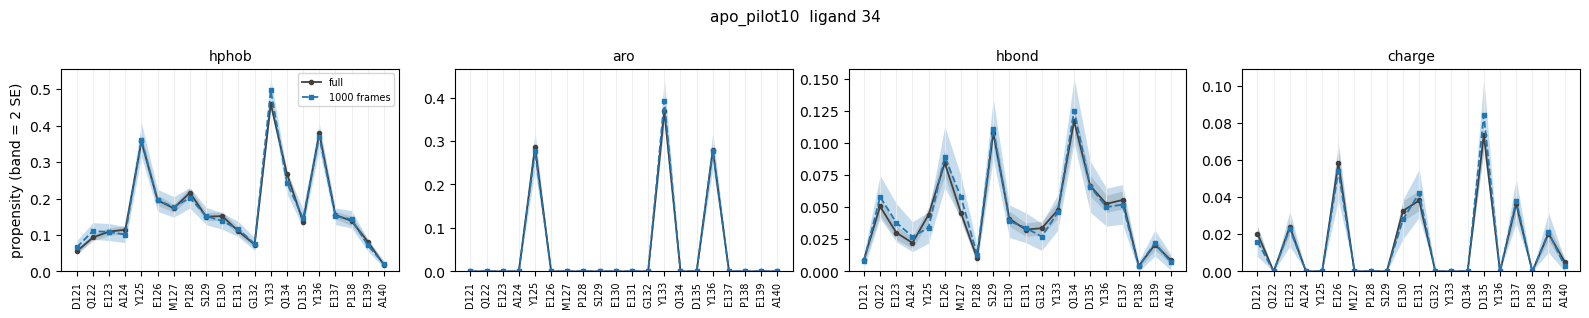

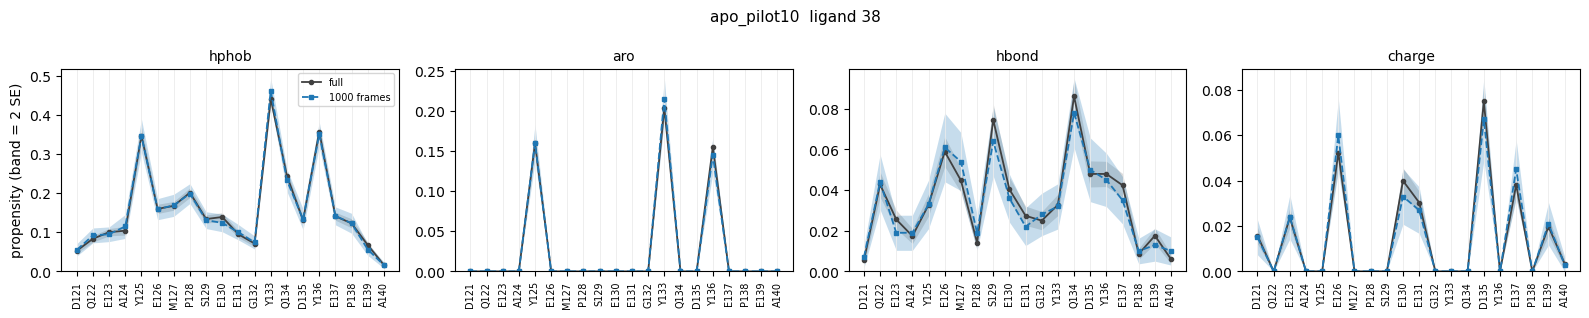

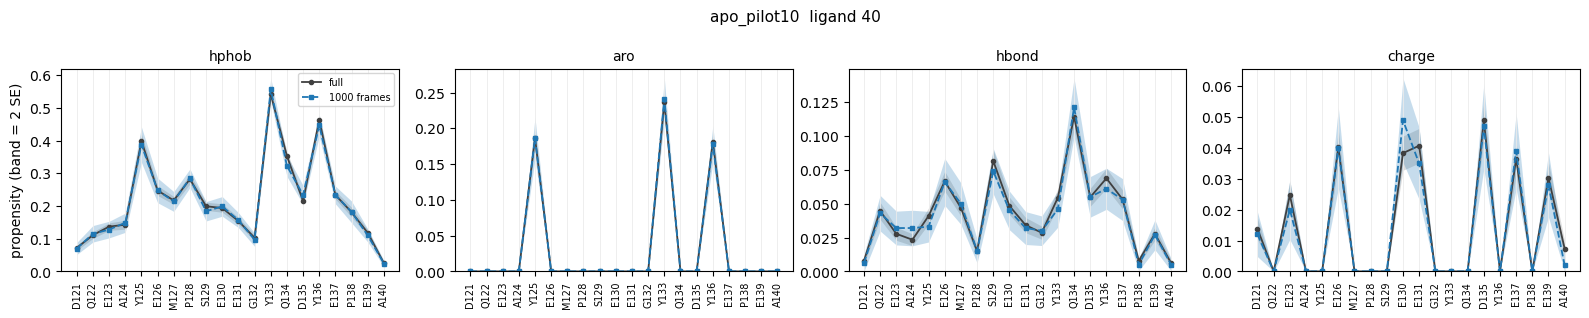

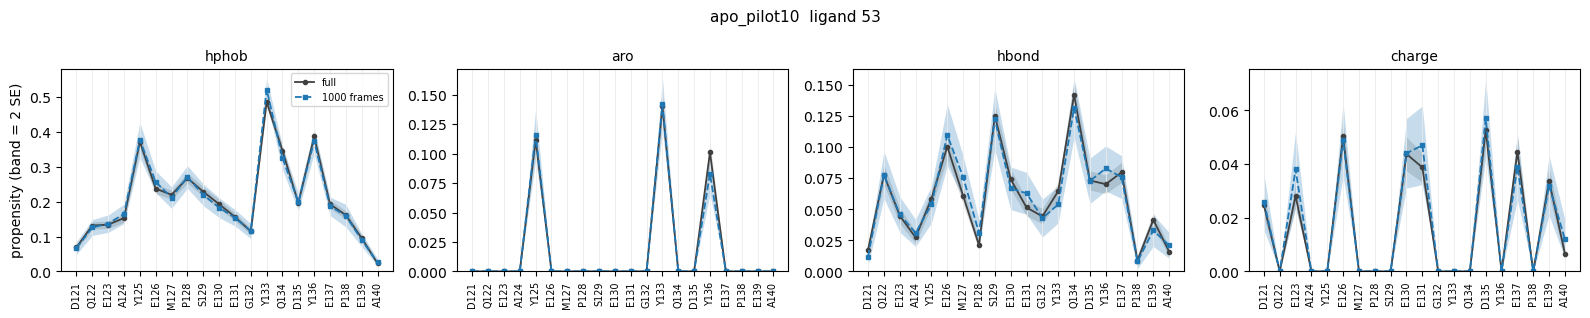

In [6]:
for (job, lig), prof in sorted(profs.items()):
    if job == "apo_pilot10":
        st.plot_propensity(job, lig, prof)
        plt.show()

### holo_pilot10

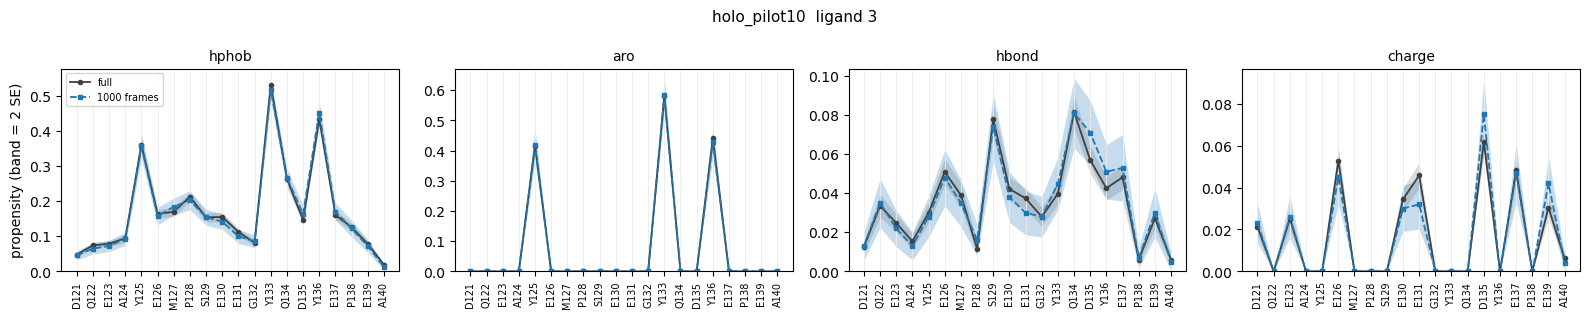

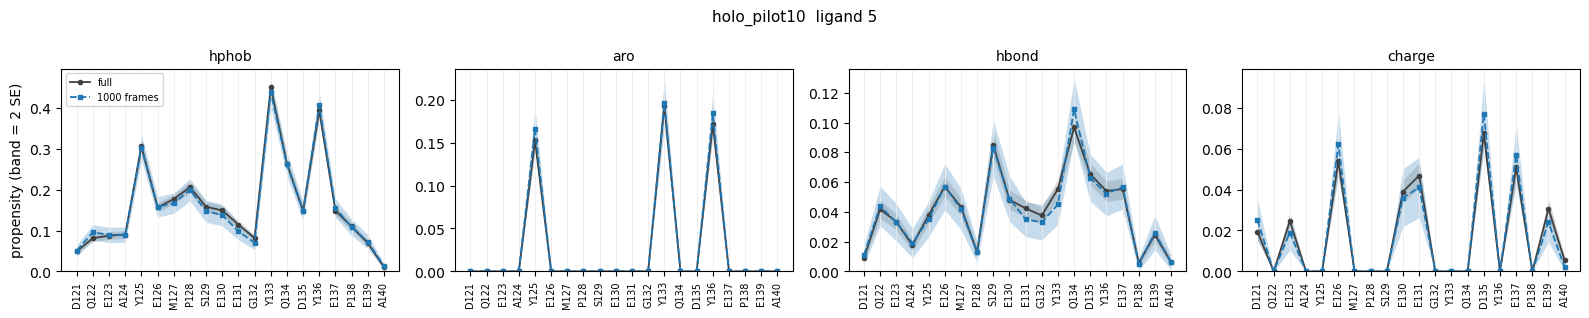

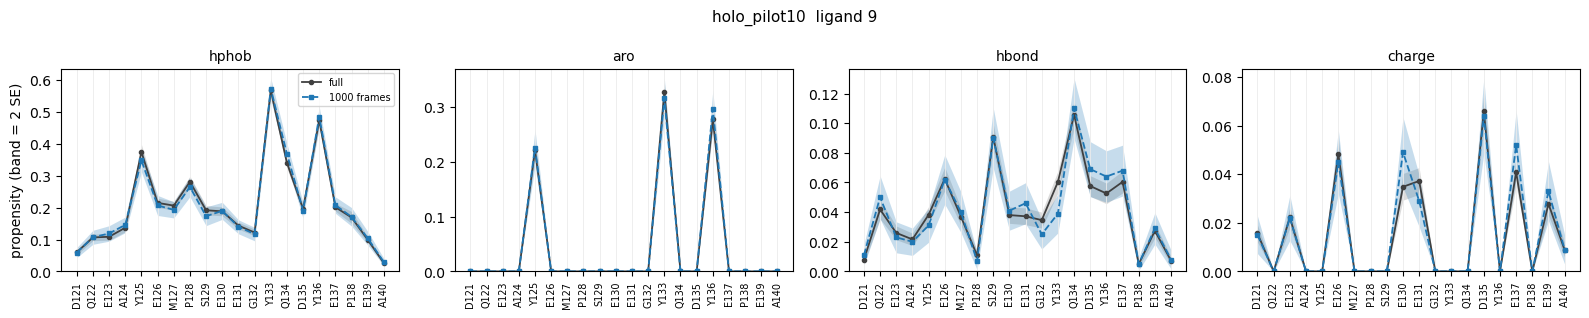

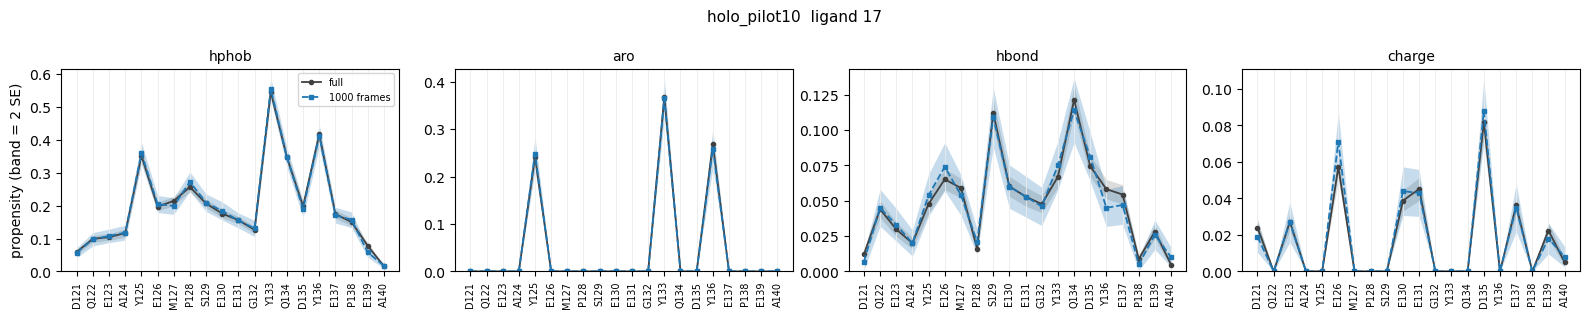

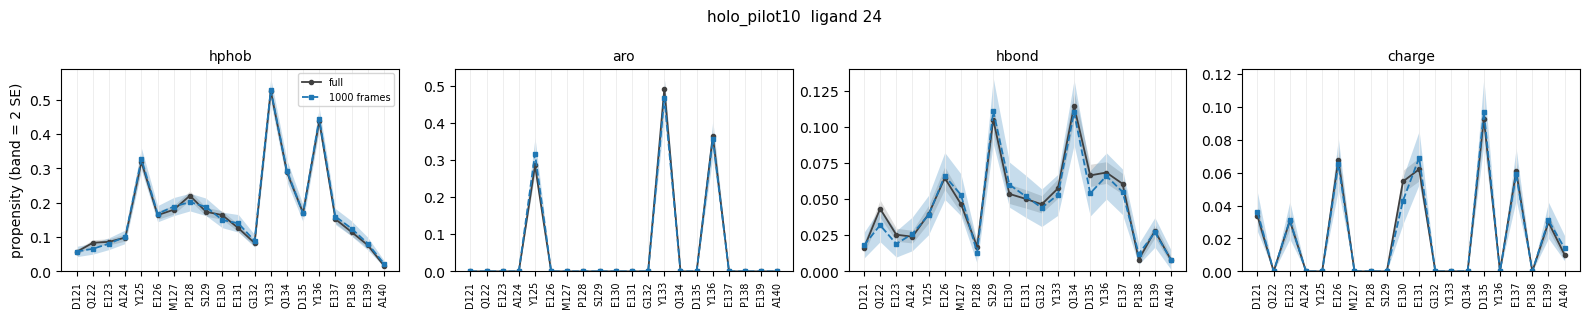

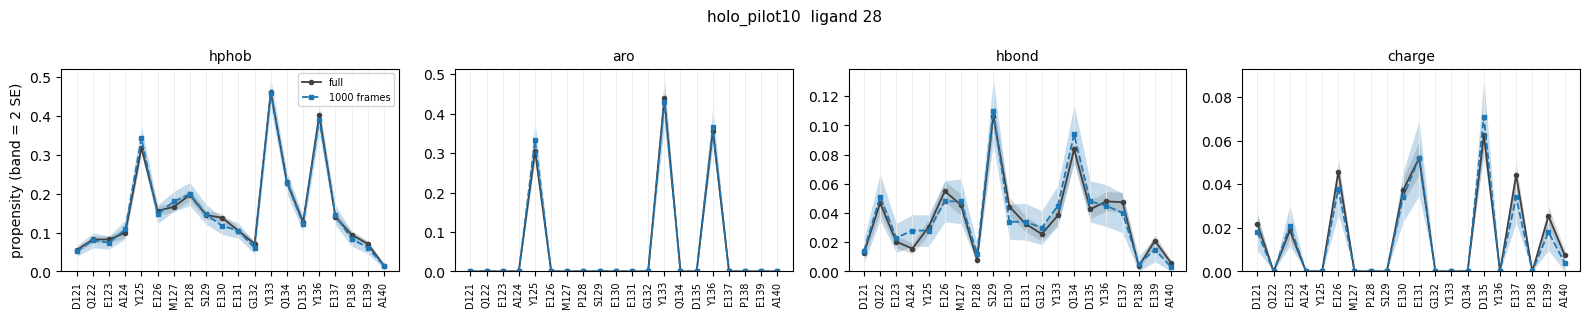

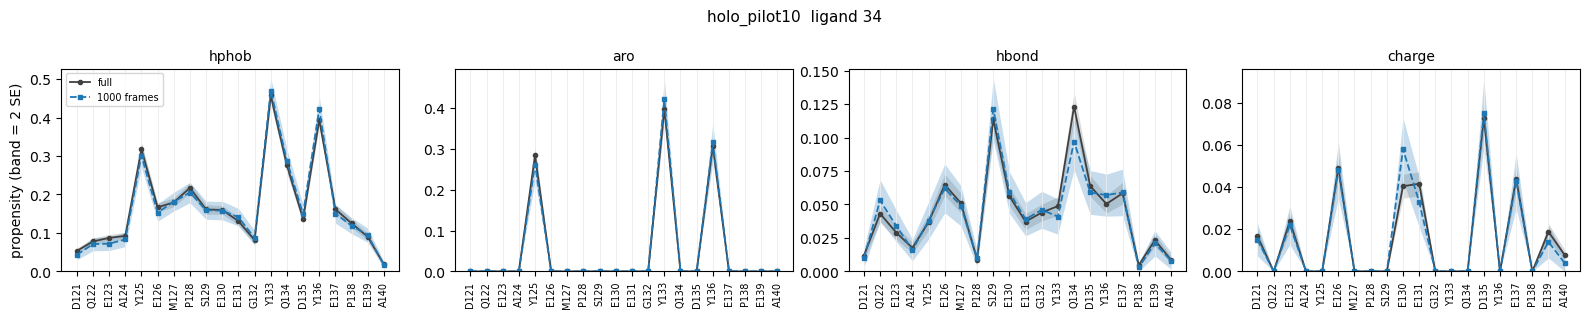

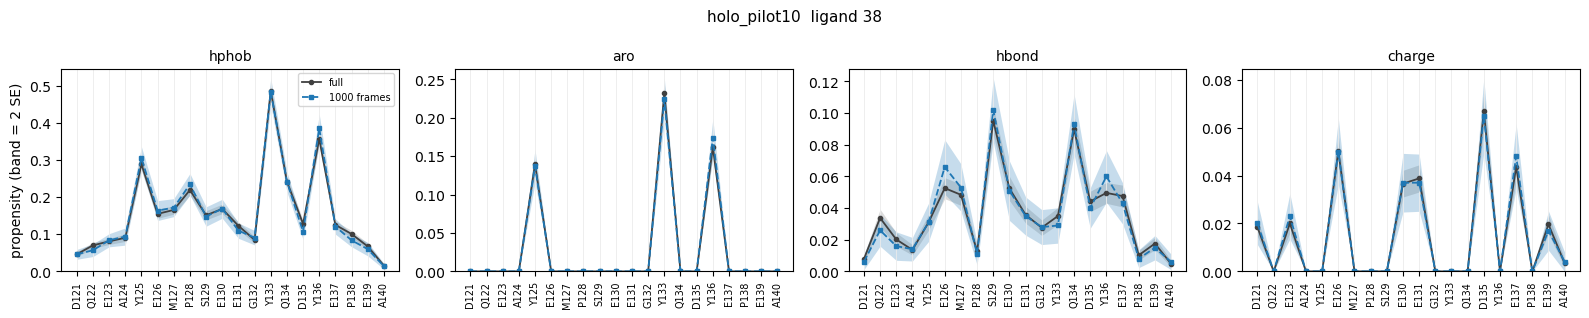

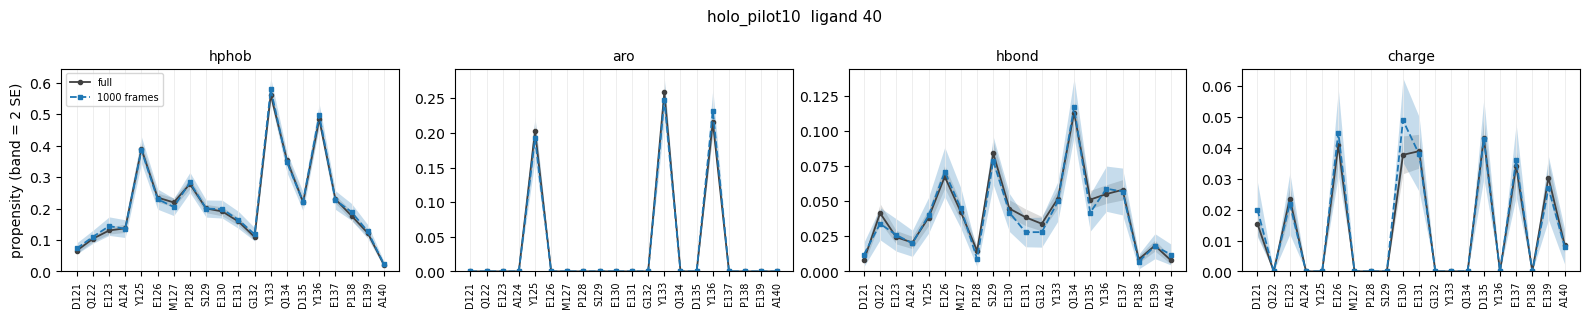

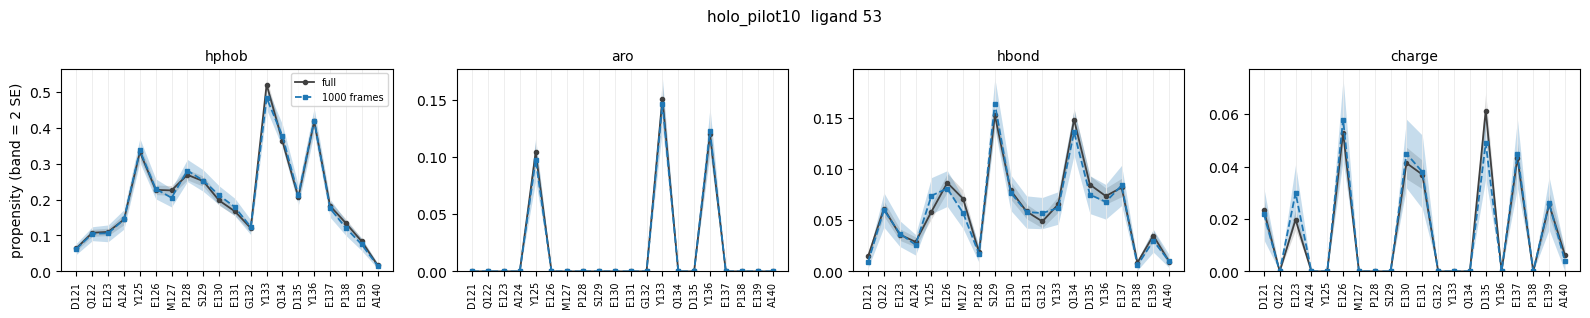

In [7]:
for (job, lig), prof in sorted(profs.items()):
    if job == "holo_pilot10":
        st.plot_propensity(job, lig, prof)
        plt.show()

### apo_remaining37

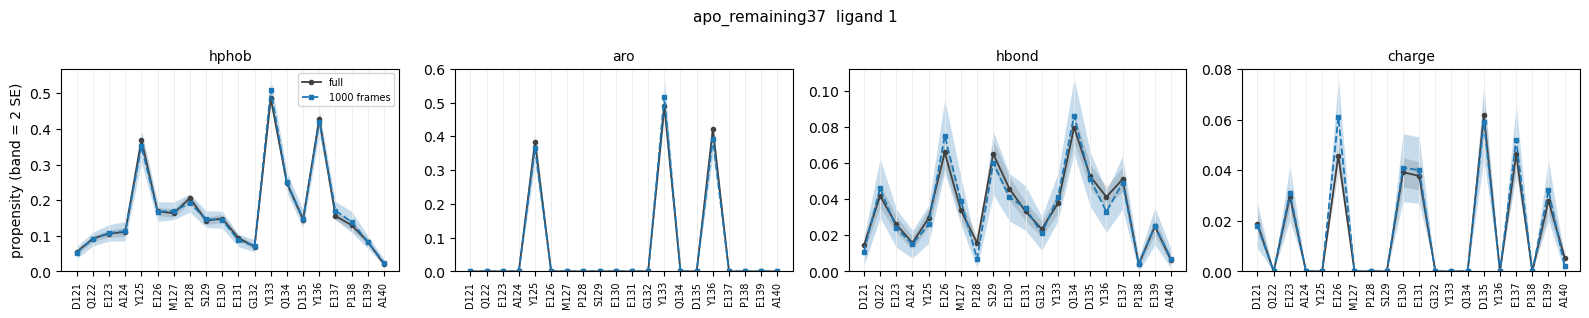

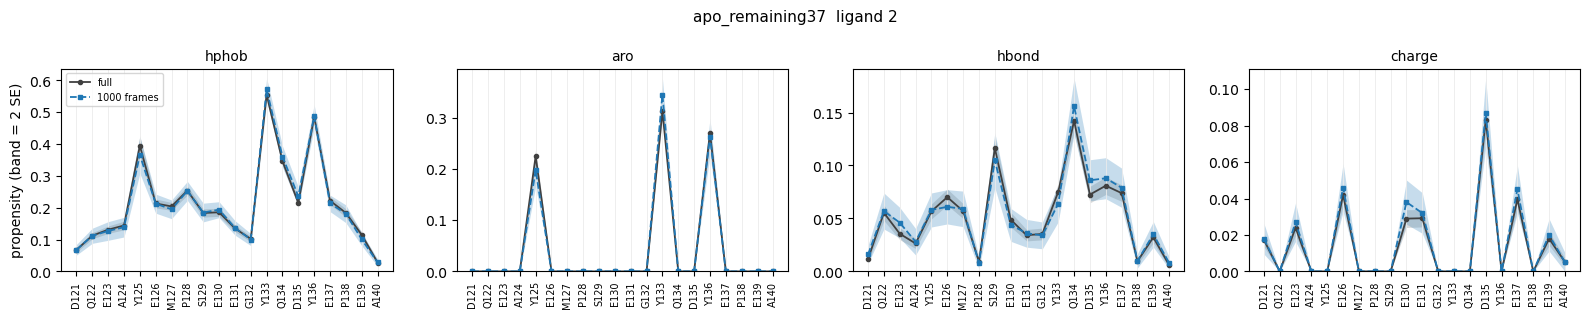

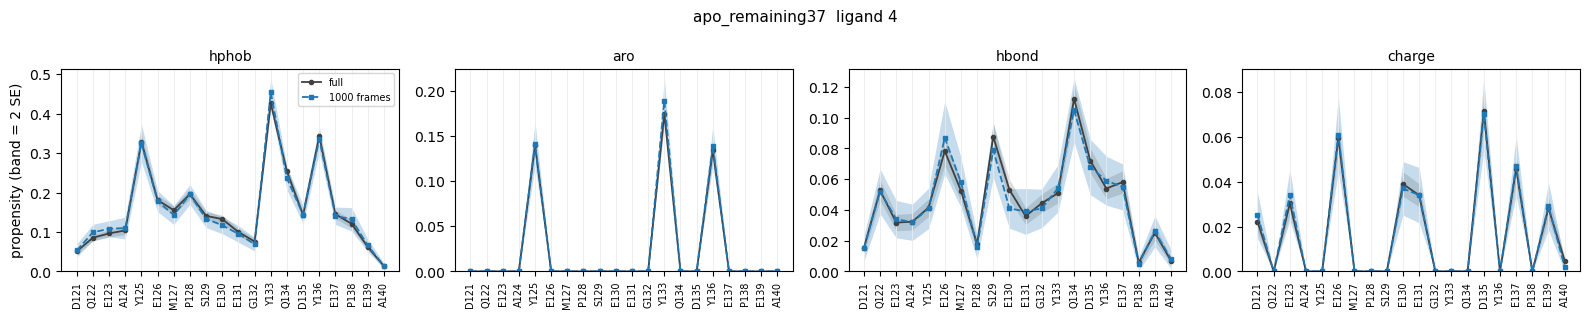

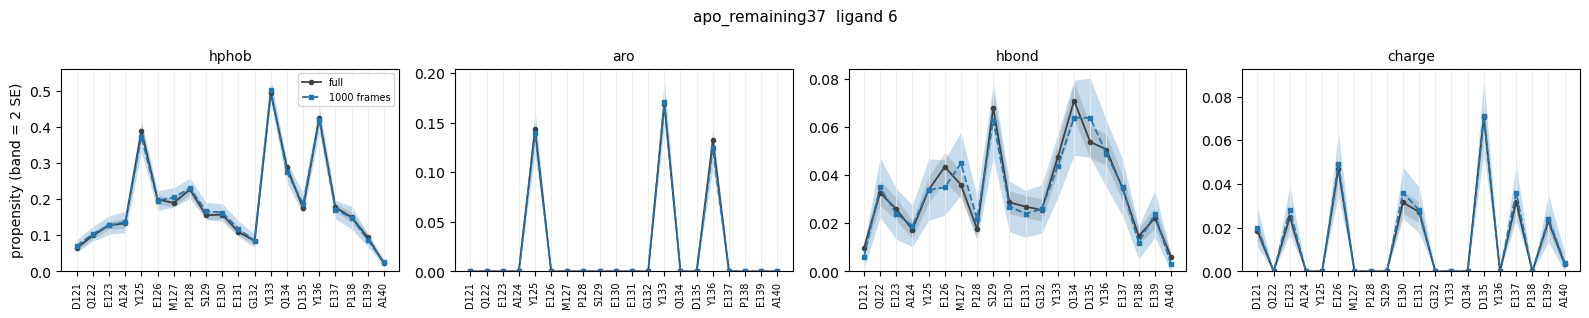

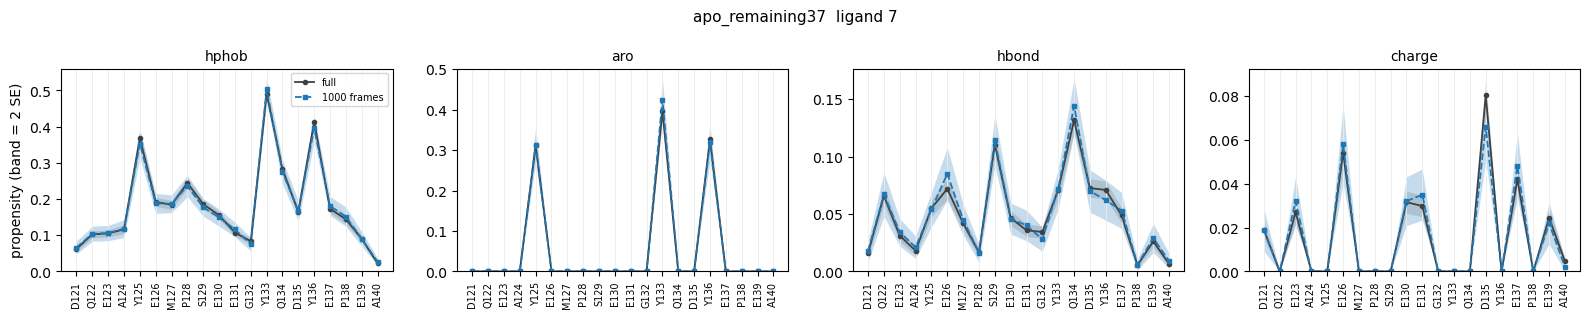

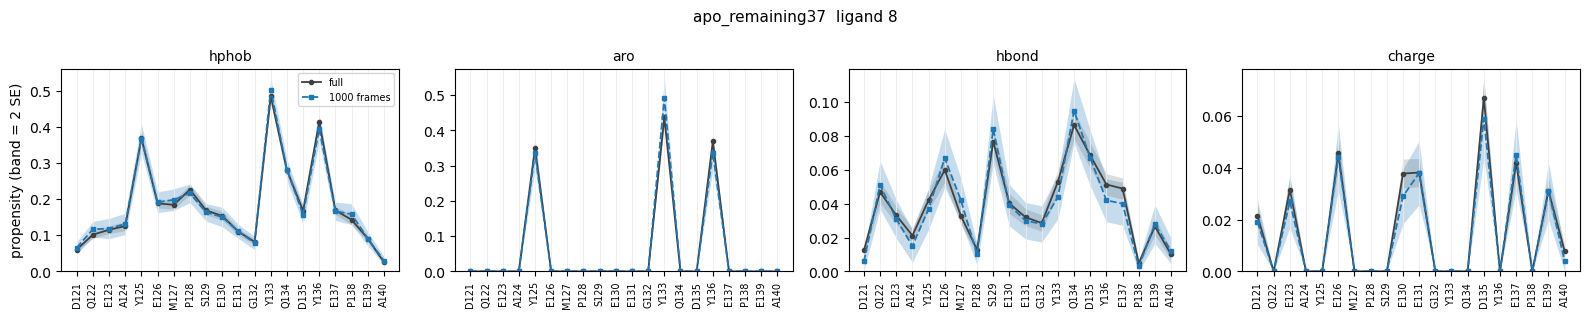

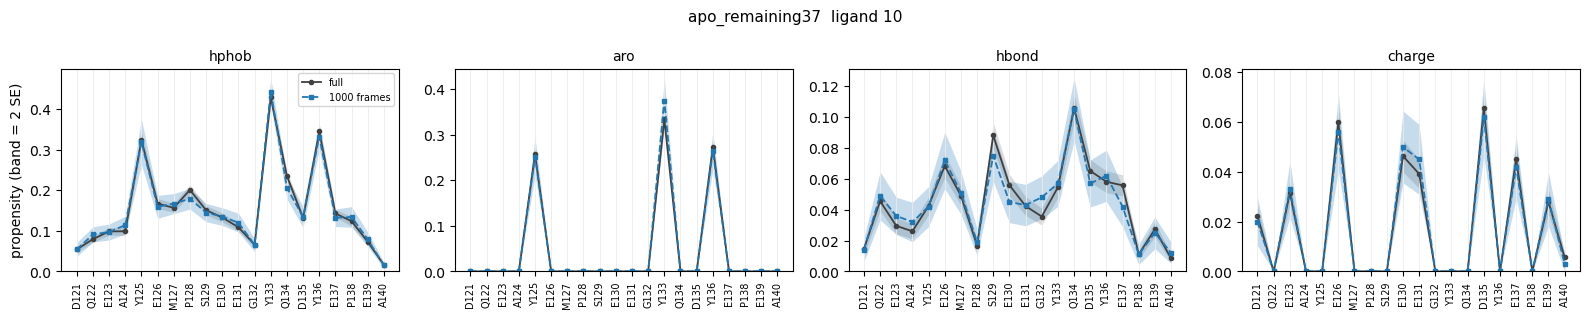

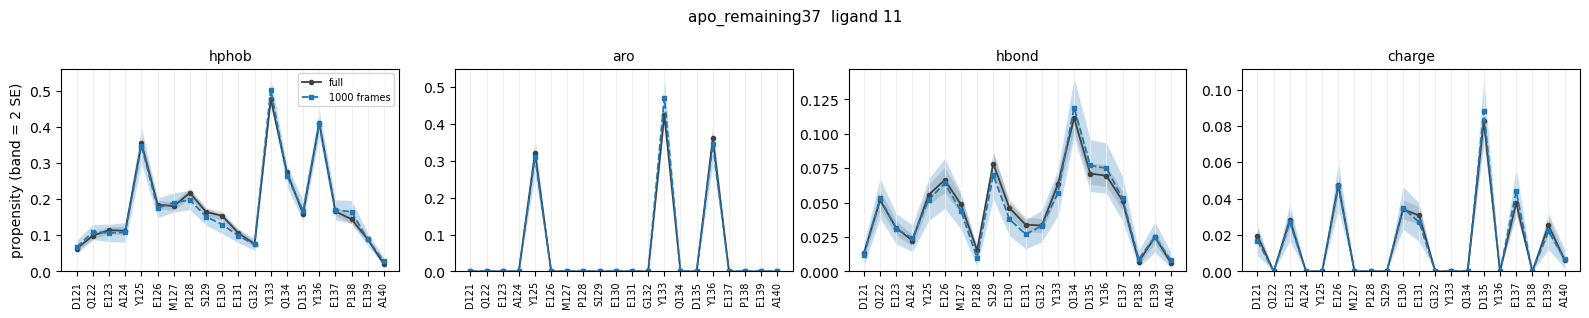

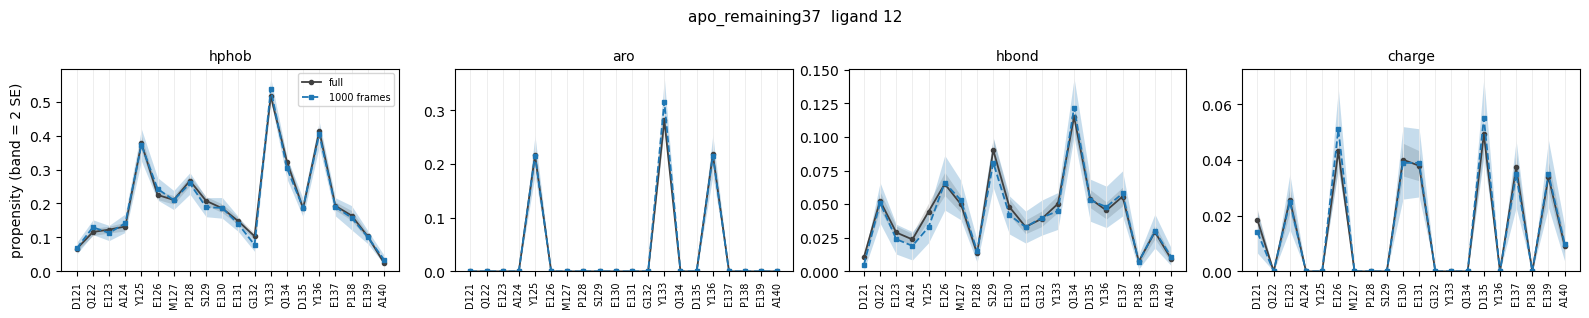

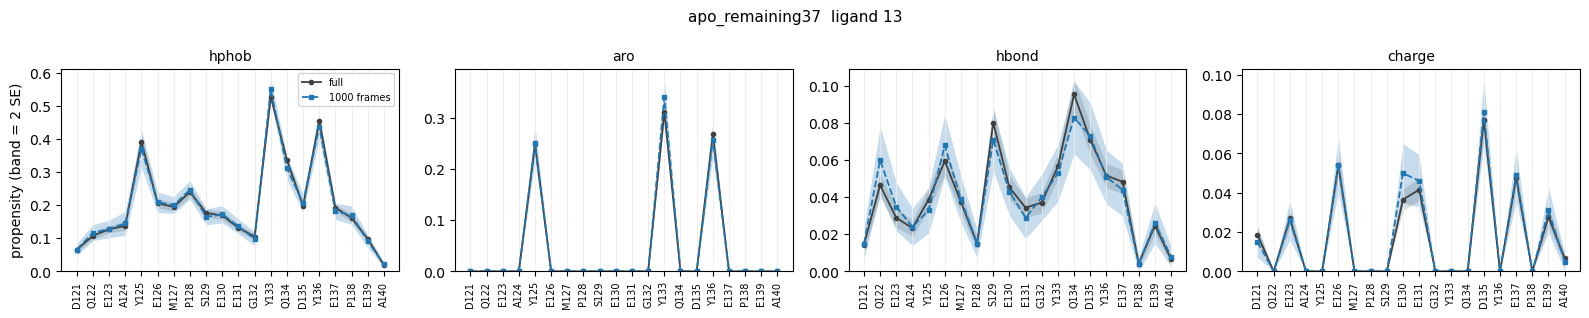

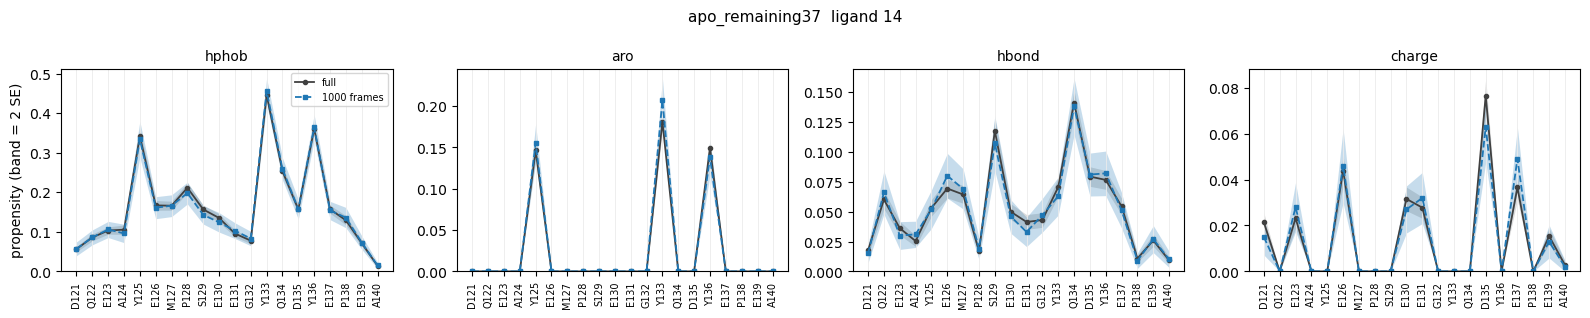

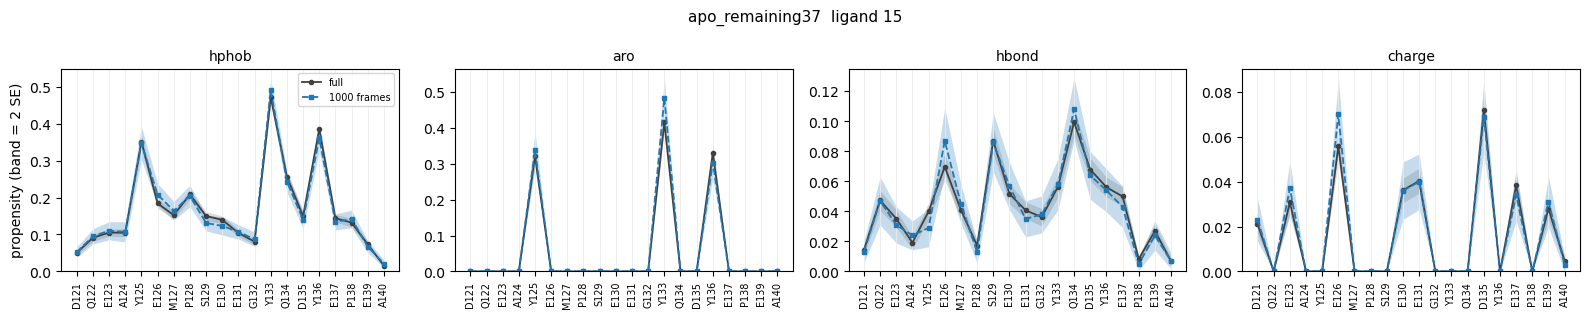

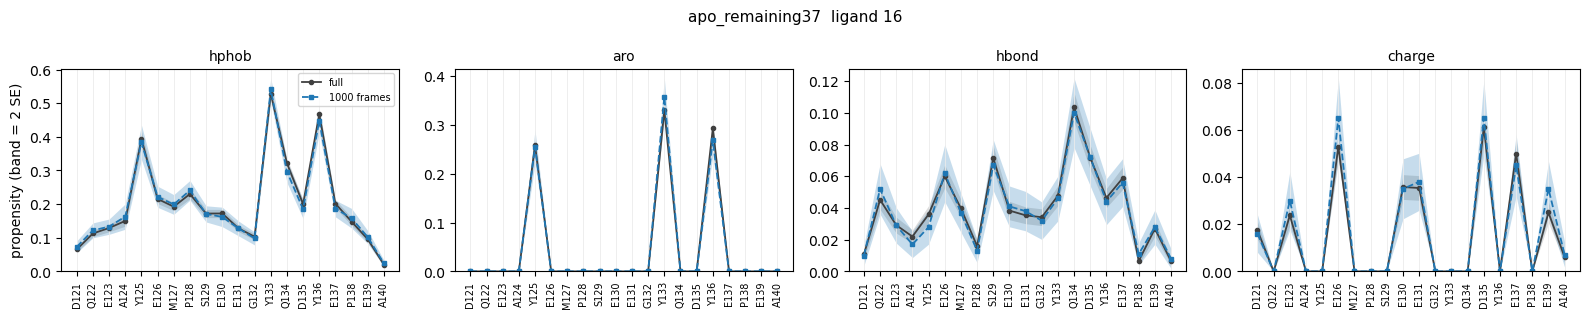

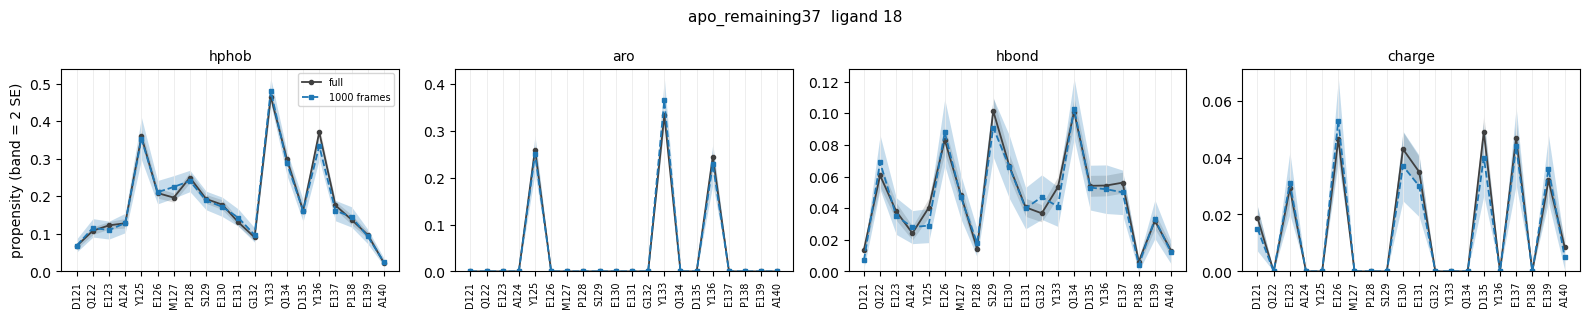

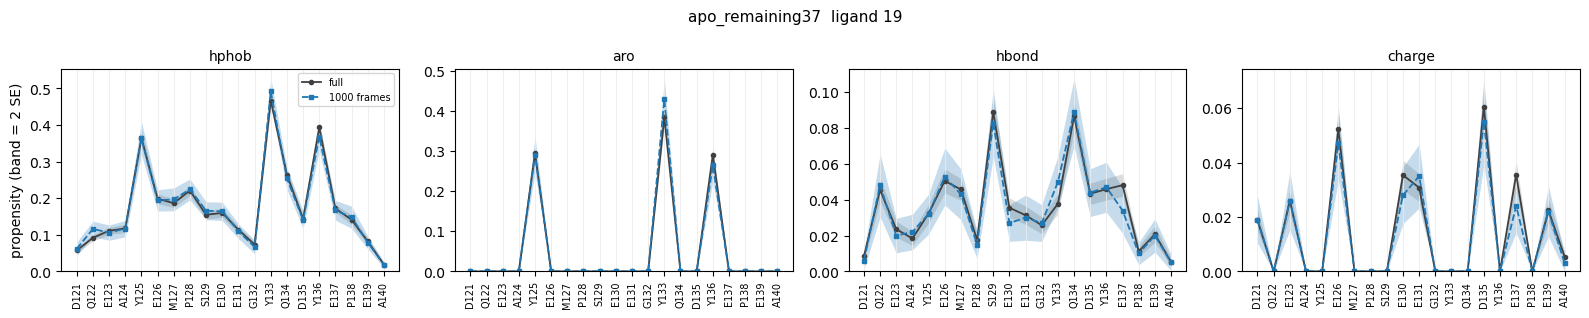

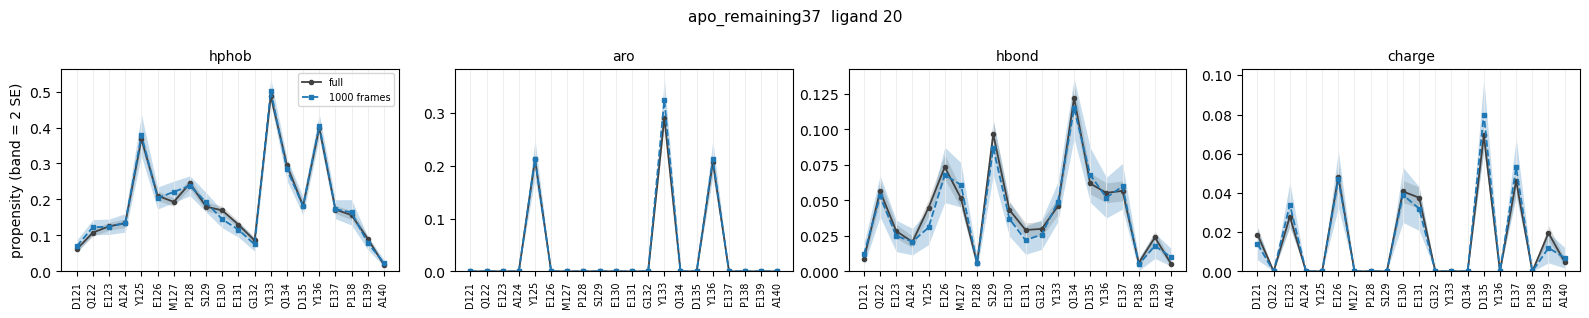

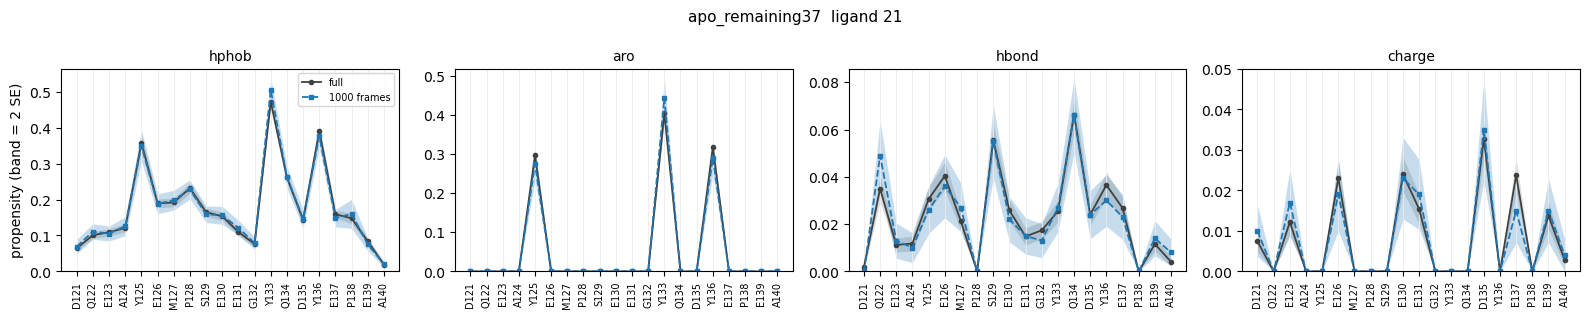

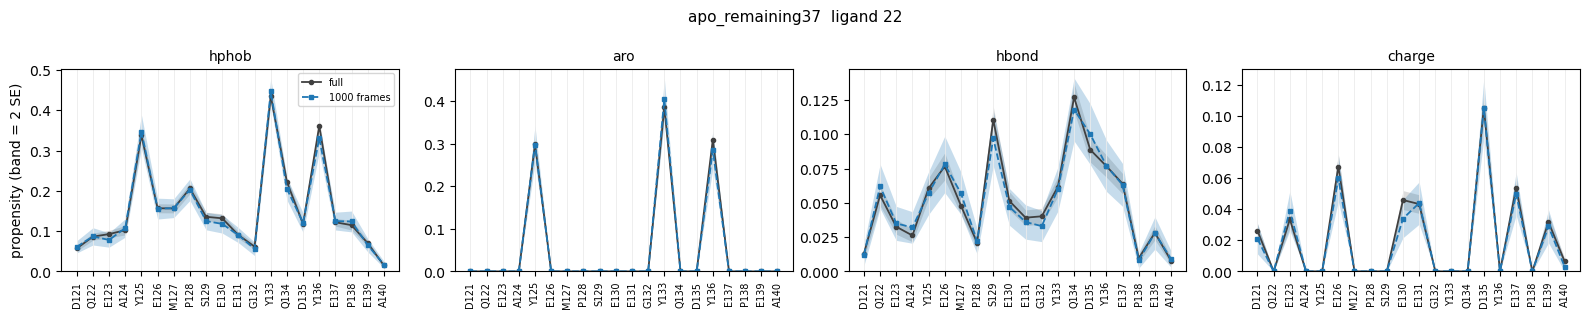

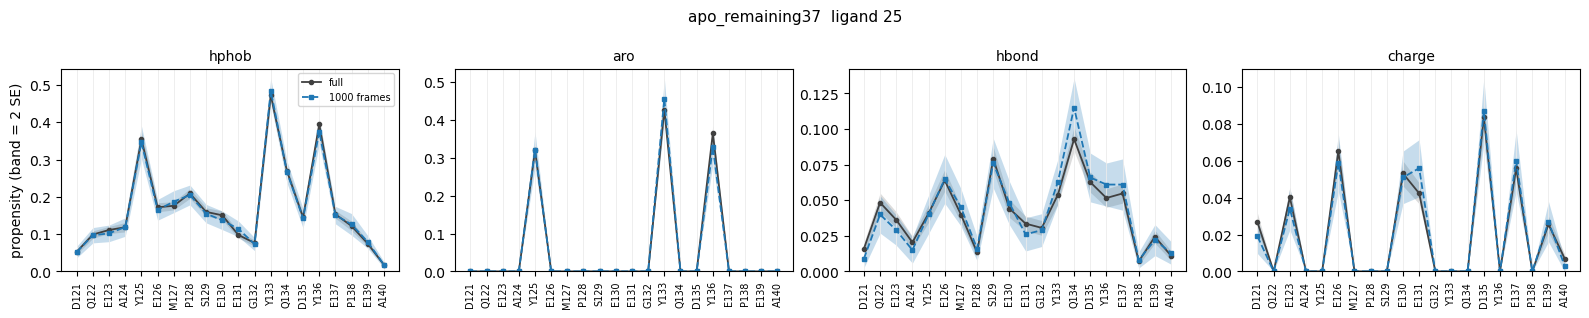

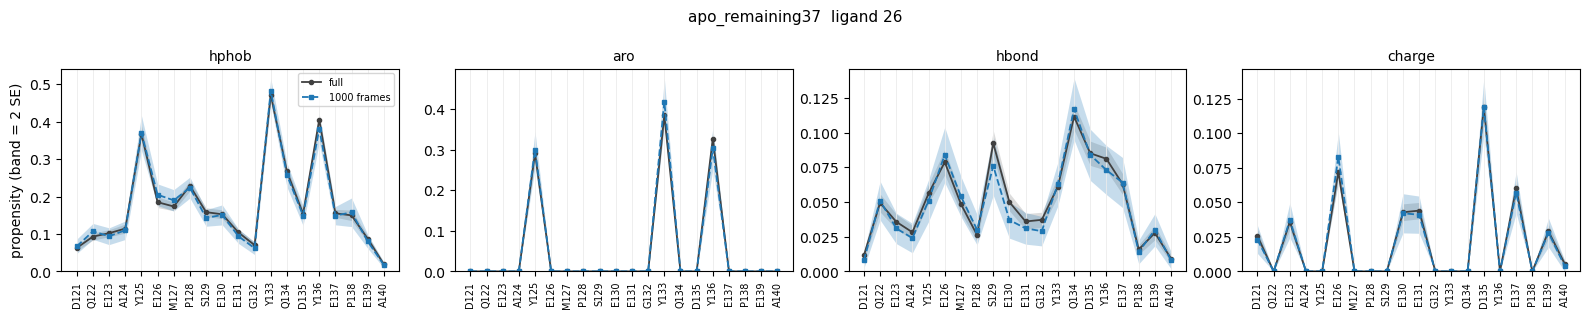

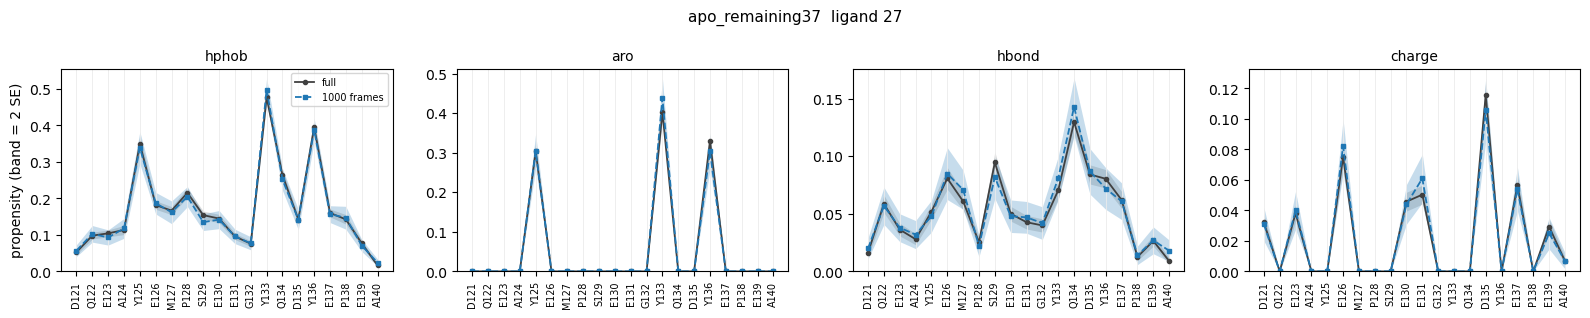

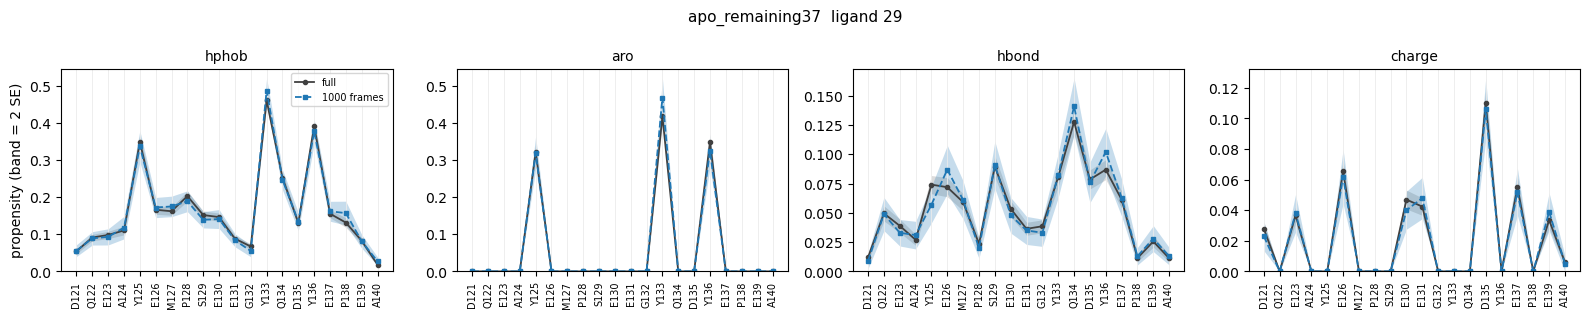

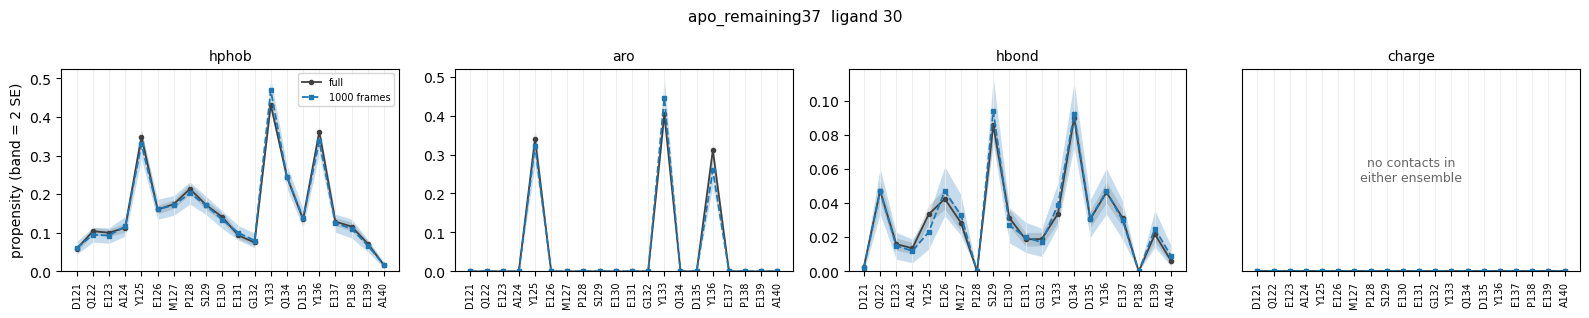

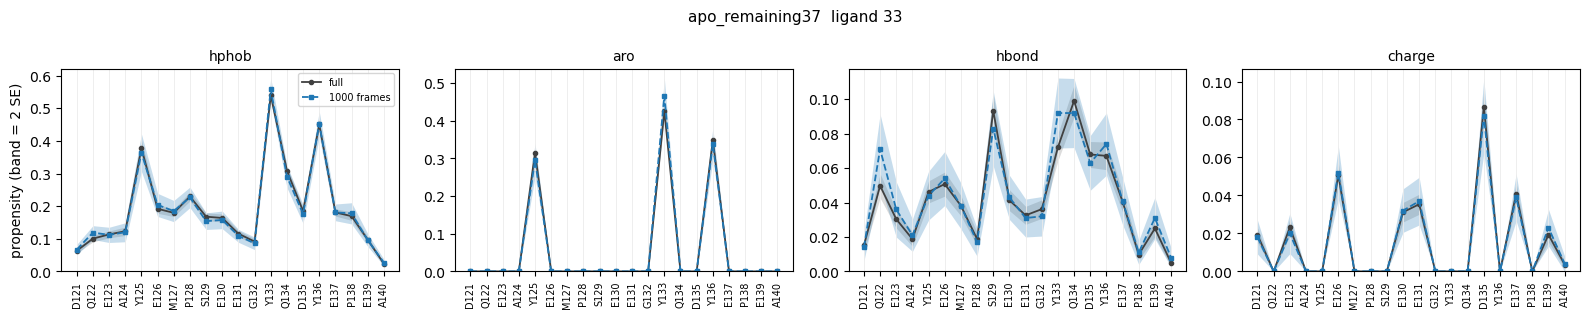

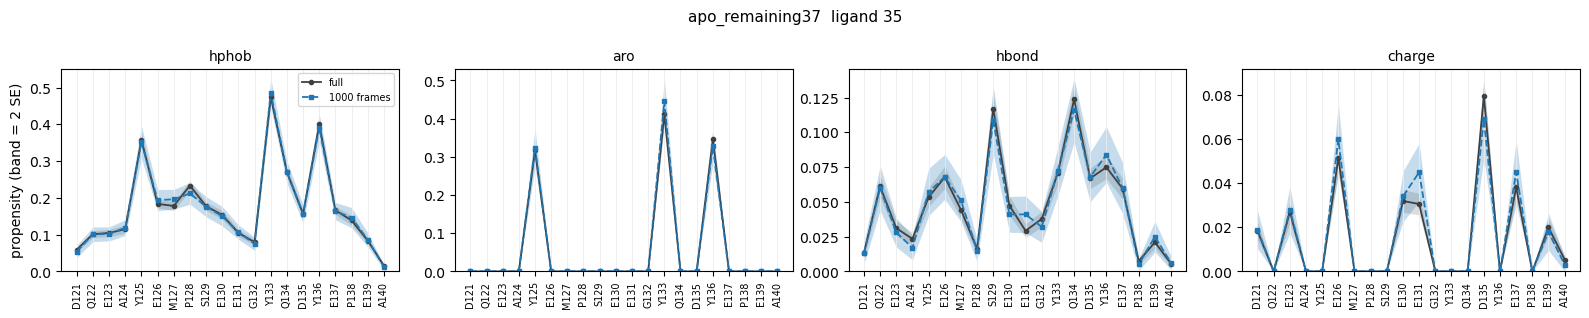

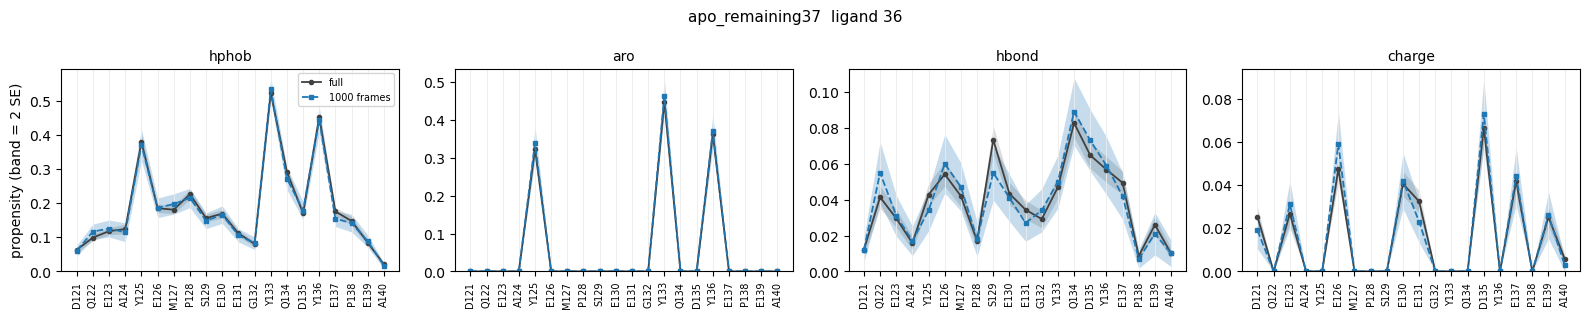

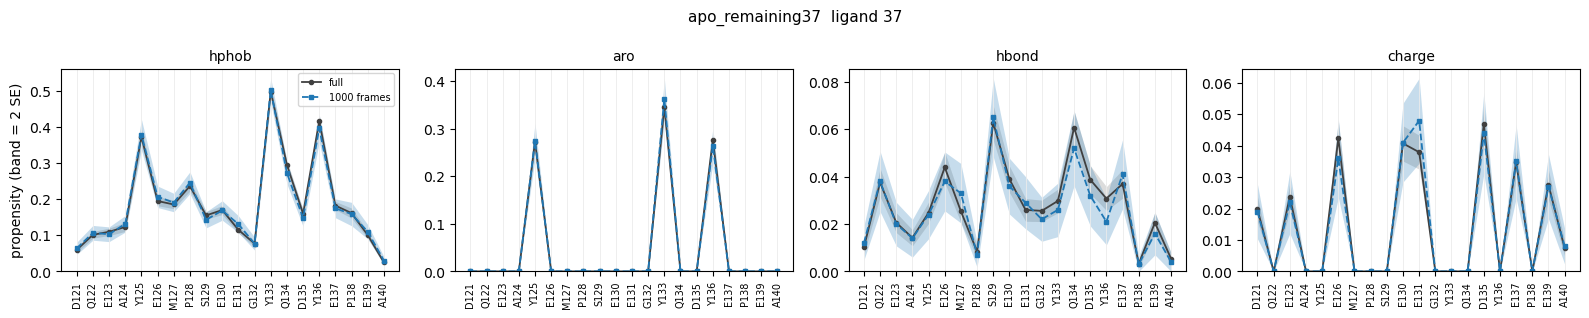

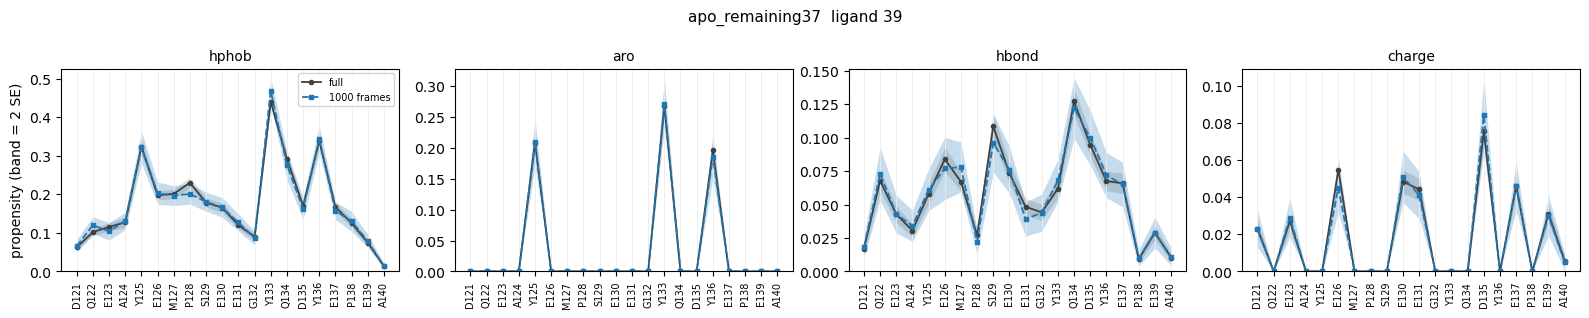

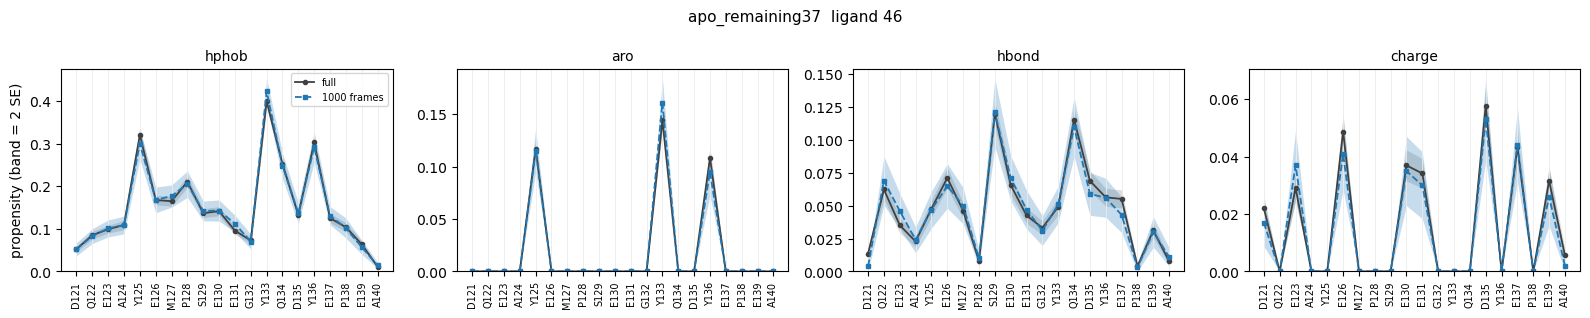

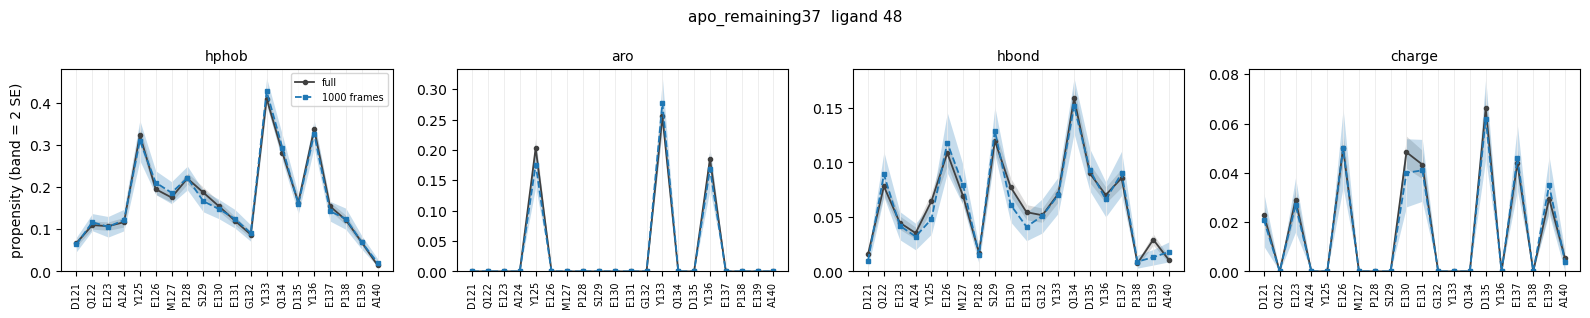

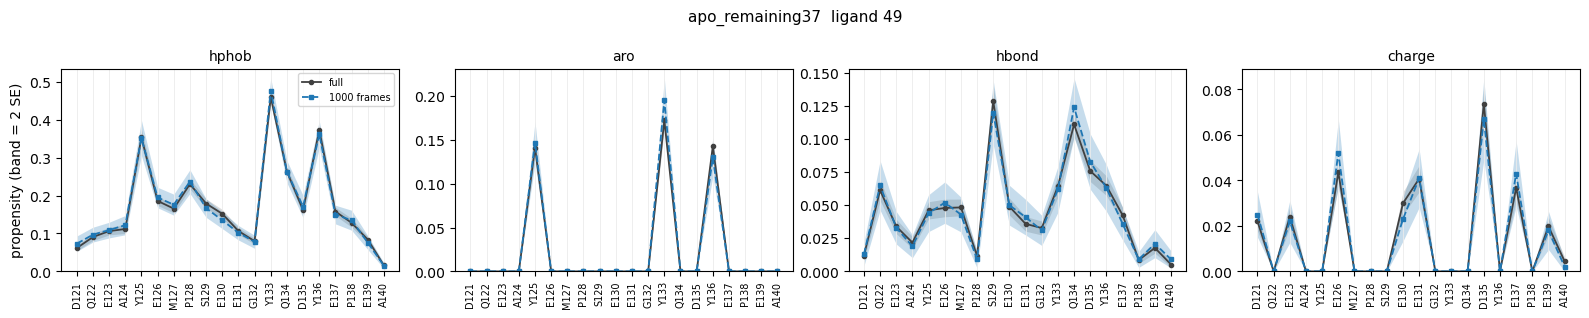

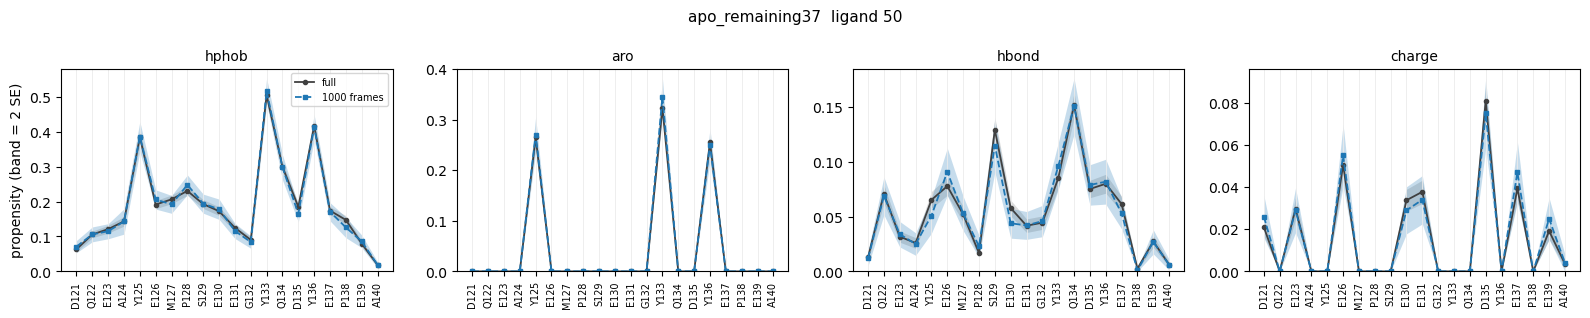

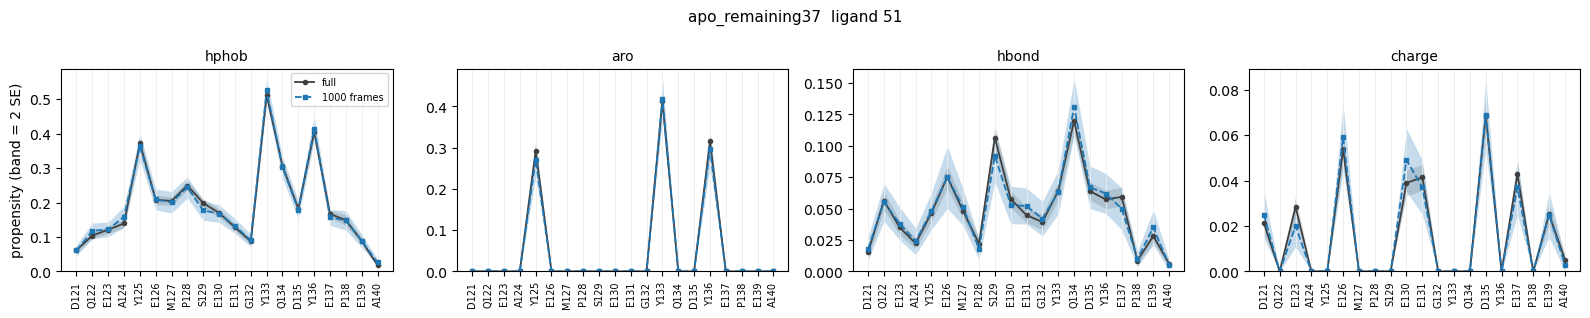

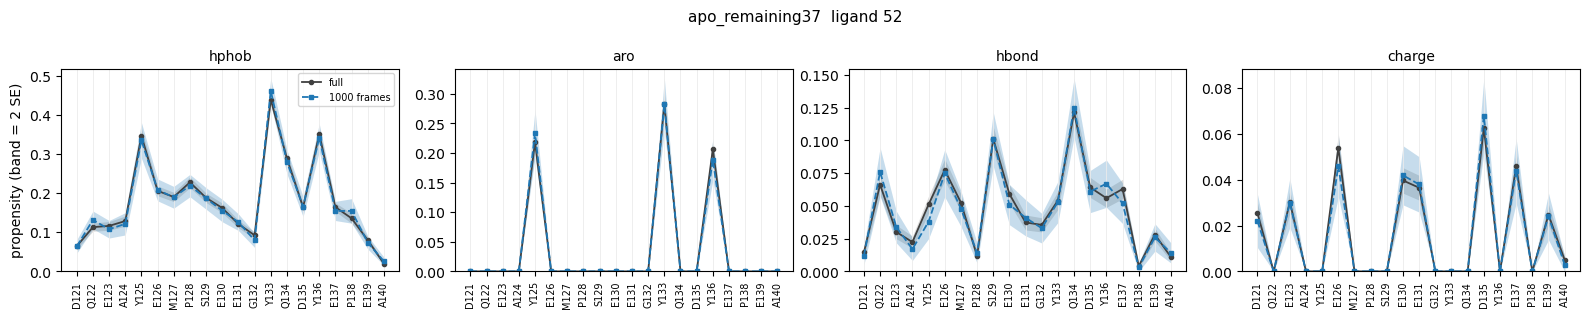

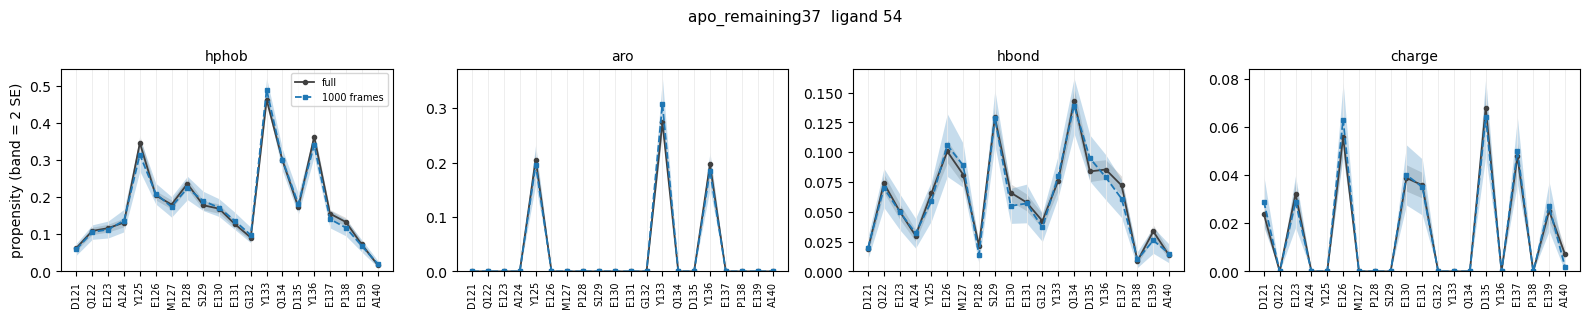

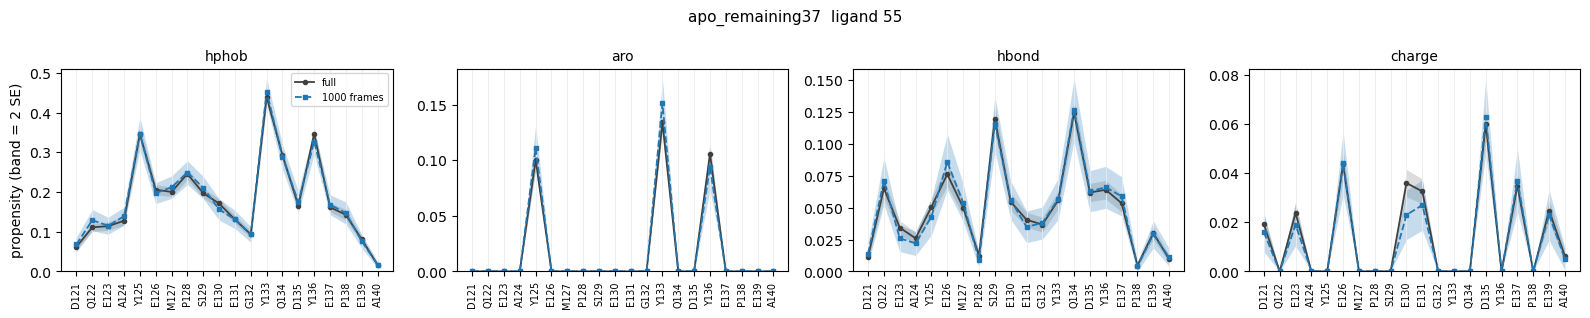

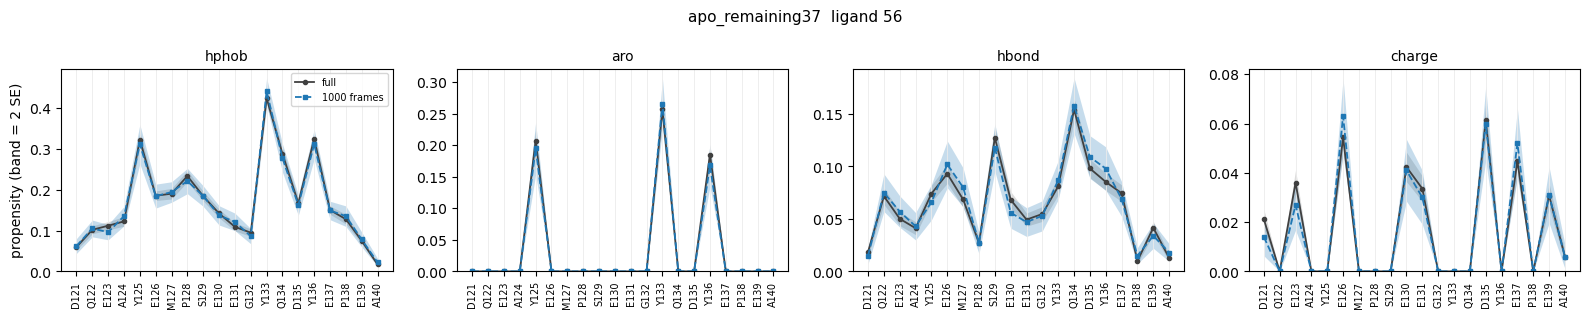

In [8]:
for (job, lig), prof in sorted(profs.items()):
    if job == "apo_remaining37":
        st.plot_propensity(job, lig, prof)
        plt.show()

### trio_apo

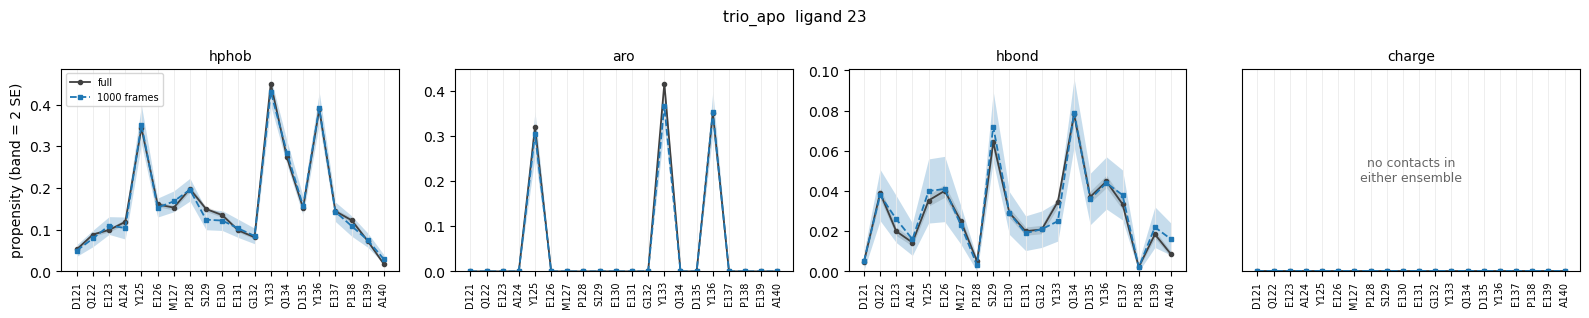

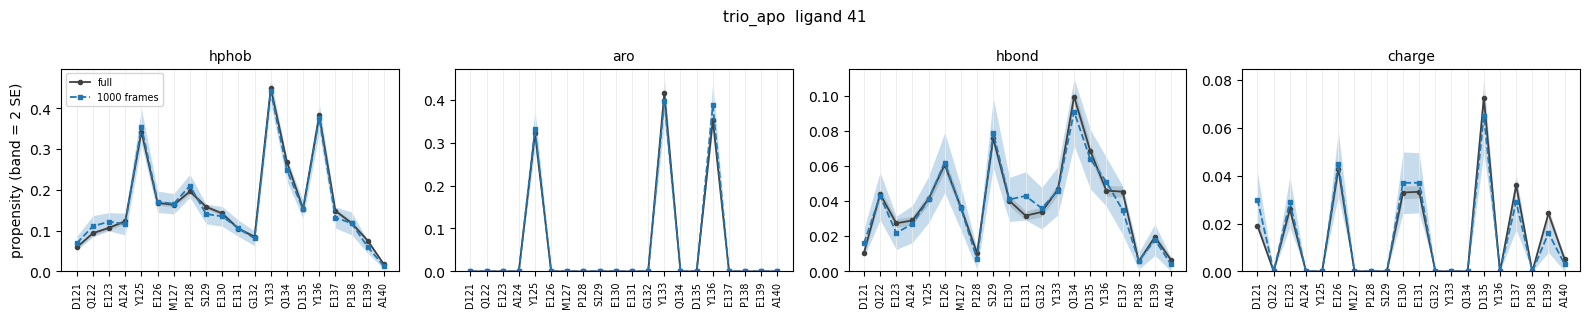

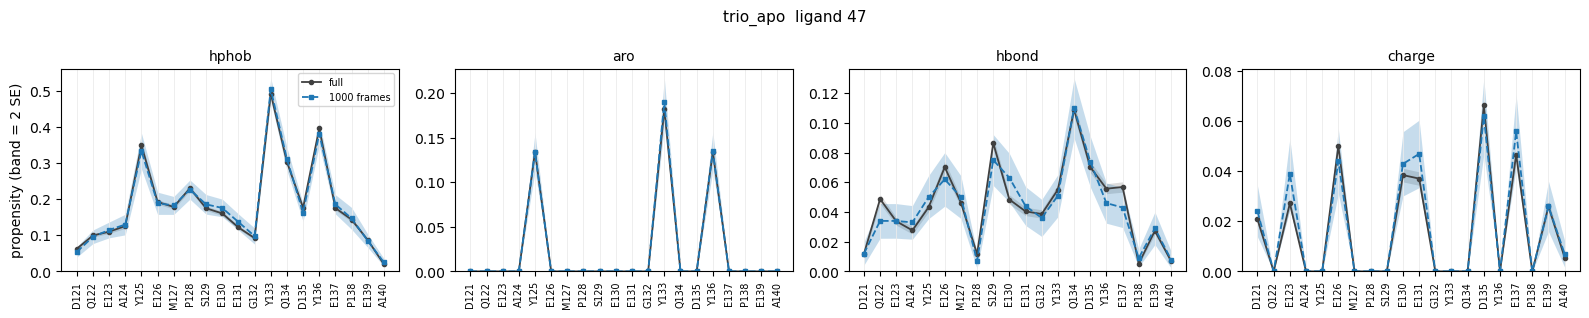

In [9]:
for (job, lig), prof in sorted(profs.items()):
    if job == "trio_apo":
        st.plot_propensity(job, lig, prof)
        plt.show()

## Verdict

In [10]:
print("\n".join(st.verdict(srows, prows)))

mean scores: 60/60 ligands, 1000-frame value within 2 SE of the full value
hphob  : residues within 2 SE 98.4% (worst ligand 90%), profile r median 0.996, peak residue kept (or tied) 60/60
aro    : residues within 2 SE 97.2% (worst ligand 67%), profile r median 0.998, peak residue kept (or tied) 60/60
hbond  : residues within 2 SE 96.8% (worst ligand 79%), profile r median 0.980, peak residue kept (or tied) 59/60
charge : residues within 2 SE 98.0% (worst ligand 75%), profile r median 0.988, peak residue kept (or tied) 58/58
(~95% within 2 SE is what sampling noise alone gives)


In [11]:
# ligands or interaction types that did not reproduce, if any
bad_scores = [r for r in srows if not r["agree"]]
bad_props = [r for r in prows if np.isfinite(r["frac_within_2se"]) and r["frac_within_2se"] < 0.85]
print(f"scores outside 2 SE: {len(bad_scores)}")
for r in bad_scores:
    print(f"  {r['job']} lig{r['lig']}: full {r['mean_full']:.3f}+/-{r['se_full']:.3f}  "
          f"{N_FRAMES} frames {r['mean_sub']:.3f}+/-{r['se_sub']:.3f}")
print(f"ligand x type with < 85% of residues within 2 SE: {len(bad_props)}")
for r in bad_props:
    print(f"  {r['job']} lig{r['lig']} {r['type']}: {r['frac_within_2se']:.0%}, "
          f"peak {r['peak_full']} -> {r['peak_sub']}")

scores outside 2 SE: 0
ligand x type with < 85% of residues within 2 SE: 7
  apo_pilot10 lig17 aro: 67%, peak Y133 -> Y133
  apo_pilot10 lig28 charge: 75%, peak D135 -> D135
  apo_pilot10 lig53 aro: 67%, peak Y133 -> Y133
  apo_remaining37 lig2 aro: 67%, peak Y133 -> Y133
  apo_remaining37 lig15 aro: 67%, peak Y133 -> Y133
  apo_remaining37 lig30 aro: 67%, peak Y133 -> Y133
  apo_remaining37 lig48 hbond: 79%, peak Q134 -> Q134
